<a href="https://colab.research.google.com/github/itgery/stattest/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22Lab01_BUPA_liver_disorders_READY_ipynb%22%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="lab01-sprint-1"></a>
# Lab01 - sprint 1

## Оглавление

- [Зачин](#intro)
- [Датасет](#dataset)
- [Настройка среды](#setup)
- [Вспомогательные функции](#helpers)
- [Загрузка данных](#data-loading)
- [Объекты исследования](#objects)
- [Первая случайная величина: drinks](#var1)
  - [EDA & распределение](#eda1)
    - [EDA](#eda1-desc)
    - [Распределение](#dist1)
  - [Гипотеза о нормальности](#hyp1)
  - [Математическая модель](#model1)
  - [Нормализация / Стандартизация](#norm1)
  - [Независимость и оценка](#indep1)
- [Вторая случайная величина: gammagt](#var2)
  - [EDA & распределение](#eda2)
    - [EDA](#eda2-desc)
    - [Распределение](#dist2)
  - [Гипотеза о нормальности](#hyp2)
  - [Математическая модель](#model2)
  - [Нормализация / Стандартизация](#norm2)
  - [Независимость и оценка](#indep2)
- [Третья случайная величина: sgot](#var3)
  - [EDA & распределение](#eda3)
    - [EDA](#eda3-desc)
    - [Распределение](#dist3)
  - [Гипотеза о нормальности](#hyp3)
  - [Математическая модель](#model3)
  - [Нормализация / Стандартизация](#norm3)
  - [Независимость и оценка](#indep3)
- [Связь величин](#correlation)
- [Проверка гипотезы](#hypothesis-test)
- [Сравнение с нормой](#reference)
- [Резюме лабораторной работы](#summary)
- [Итоговые метрики и выводы](#metrics)
- [Нарушение медицинских норм](#medical)
- [Концовка](#ending)
- [Таблица категорий](#cat-mark-table)

## Зачин

> Наша история началась в маленьком Королевстве BUPA, где жили три исследователя: две девушки, изучающие алхимию, и юноша — их верный спутник. Они учились в лучшей академии Королевства, которая называлась "Талантливые и мотивированные".  
>
> Однажды в Королевстве прошёл слух: в главной торговой лавке продают потдельный алкоголь, от которого страдает печень. Лавку собирались закрыть, но там продавалась любимая наливка наших исследователей.
>
> Чтобы спасти любимый напиток, студенты проникли в кабинет главного тиуна — полицейского по нашему, и выкрали все бумаги связанные с этим делом, там были анализы всех, кто пил алкоголь из этой торговой лавки, изучив эти данные исследователи собирались понять, вредит ли этот алкоголь печени.
>
> — Нужно срочно уезжать! — сказала одна из девушек, увидев объявление о розыске на доске.
>
> Исследователи выбрались через чашу и пустились в бега. Охрана с башни могла заметить их в любой момент, поэтому пришлось ползти гуськом через густой лес на границе города.
>
> На другом конце леса их ждал Старец. В его доме, в соседнем городе, четверо собрались за столом и открыли датасет с данными...

<a id="dataset-description"></a>
## Датасет


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #ffffff; border: 1px solid #e0e0e0; border-radius: 6px; padding: 24px; margin: 15px 0; box-shadow: 0 1px 3px rgba(0,0,0,0.04); font-family: 'Georgia', serif; line-height: 1.6;">

    <h3 style="color: #222; margin-top: 0; margin-bottom: 20px; font-size: 20px; border-bottom: 1px solid #e0e0e0; padding-bottom: 10px;">Dataset</h3>

    <h4 style="color: #444; margin-top: 20px; margin-bottom: 10px; font-size: 16px;">Описание датасета</h4>

    <table style="width: 100%; border-collapse: collapse; font-size: 15px; margin-bottom: 20px;">
        <tr>
            <td style="padding: 8px 12px; color: #555; width: 120px;"><b>Название:</b></td>
            <td style="padding: 8px 12px; color: #222;">BUPA Liver Disorders</td>
        </tr>
        <tr style="background-color: #fafafa;">
            <td style="padding: 8px 12px; color: #555;"><b>Автор:</b></td>
            <td style="padding: 8px 12px; color: #222;">BUPA Medical Research Ltd.</td>
        </tr>
        <tr>
            <td style="padding: 8px 12px; color: #555;"><b>Размер:</b></td>
            <td style="padding: 8px 12px; color: #222;">345 наблюдений, 7 полей</td>
        </tr>
    </table>

    <h4 style="color: #444; margin-top: 20px; margin-bottom: 10px; font-size: 16px;">Поля</h4>

    <ol style="font-size: 15px; color: #333; line-height: 1.8; padding-left: 25px; margin-bottom: 20px;">
        <li><b>mcv</b> — средний объём эритроцита</li>
        <li><b>alkphos</b> — щелочная фосфатаза</li>
        <li><b>sgpt</b> — аланинаминотрансфераза</li>
        <li><b>sgot</b> — аспартатаминотрансфераза</li>
        <li><b>gammagt</b> — γ-глутамилтранспептидаза</li>
        <li><b>drinks</b> — количество алкогольных напитков, в эквиваленте пол-пинт (284 мл), которые человек выпивает в день</li>
        <li><b>selector</b> — техническое поле, использованное авторами для разделения на обучающую и тестовую выборки</li>
    </ol>

    <div style="border-top: 1px solid #e0e0e0; padding-top: 15px; margin-top: 20px;">
        <h4 style="color: #444; margin-top: 0; margin-bottom: 10px; font-size: 16px;">Источник</h4>
        <p style="font-size: 14px; color: #555; margin: 0; line-height: 1.6;">
            UCI Machine Learning Repository, Liver Disorders.
            DOI: <span style="font-family: monospace; background-color: #f5f5f5; padding: 2px 6px; border-radius: 3px;">10.24432/C54G67</span>
        </p>
        <p style="font-size: 14px; color: #555; margin: 10px 0 0 0; line-height: 1.6;">
            Ссылка на датасет в OpenML:
            <a href="https://www.openml.org/search?type=data&status=active&id=8&sort=runs" style="color: #1a0dab; text-decoration: none;">https://www.openml.org/search?type=data&status=active&id=8&sort=runs</a>
        </p>
    </div>
</div>
""")

Название:,BUPA Liver Disorders
Автор:,BUPA Medical Research Ltd.
Размер:,"345 наблюдений, 7 полей"




> — Ура! Это данные анализов всех мужин нашего города! То, что нужно — воскликнул юноша.


> — Нужно скорее перенести этот датасет на наши волшебные зеркала и высянить, правда ли с наливкой что-то не так. — ответила юноше одна из девушек.






## Настройка среды



> — Таак, настроим среду... — воодушевленно сказал юноша.



In [ ]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.io import arff
import gzip
import base64
import io

sns.set_style("whitegrid")  # сетка на графиках
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

pd.set_option("display.float_format", lambda x: f"{x:.4f}")

<a id="helpers"></a>
## Вспомогательные функции



> — Пропишим базовые заклинания... — продолжал молодой рыцарь.



In [ ]:
# @title
def describe_rv(series):
    s = pd.Series(series).dropna().astype(float)
    return pd.Series({
        "n": len(s),
        "mean": s.mean(),
        "median": s.median(),
        "variance_unbiased": s.var(ddof=1),
        "std_unbiased": s.std(ddof=1),
        "min": s.min(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "max": s.max(),
        "skewness": stats.skew(s, bias=False),
        "excess_kurtosis": stats.kurtosis(s, fisher=True, bias=False),
        "unique_values": s.nunique(),
    })

def ecdf_xy(series):
    x = np.sort(pd.Series(series).dropna().to_numpy(dtype=float))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

def z_standardize(series):
    s = pd.Series(series, dtype=float)
    return (s - s.mean()) / s.std(ddof=1)

def minmax_normalize(series):
    s = pd.Series(series, dtype=float)
    return (s - s.min()) / (s.max() - s.min())

def population_sample_table(population, sample):
    pop = pd.Series(population, dtype=float)
    smp = pd.Series(sample, dtype=float)
    out = pd.DataFrame({
        "population": [
            pop.mean(),
            pop.var(ddof=0),
            pop.median(),
            pop.quantile(0.25),
            pop.quantile(0.75),
        ],
        "sample": [
            smp.mean(),
            smp.var(ddof=1),
            smp.median(),
            smp.quantile(0.25),
            smp.quantile(0.75),
        ],
    }, index=["mean", "variance", "median", "Q1", "Q3"])
    out["absolute_difference"] = (out["sample"] - out["population"]).abs()
    return out

def consistency_experiment(series, sample_sizes=(20, 50, 100, 150, 250, 300),
                           repeats=1000, seed=2026):
    arr = np.asarray(series, dtype=float)
    mu = arr.mean()
    var = arr.var(ddof=0)
    rng = np.random.default_rng(seed)
    rows = []

    for n in sample_sizes:
        mean_err = []
        var_err = []

        for _ in range(repeats):
            sample = rng.choice(arr, size=n, replace=False)
            mean_err.append(abs(sample.mean() - mu))
            var_err.append(abs(sample.var(ddof=1) - var))

        rows.append([n, np.mean(mean_err), np.mean(var_err)])

    return pd.DataFrame(rows, columns=["n", "MAE_mean", "MAE_variance"])

def distribution_fit_table(series):
    x = np.asarray(series, dtype=float)

    candidates = {
        "Normal": (stats.norm, {}),
        "Lognormal": (stats.lognorm, {"floc": 0}),
        "Gamma": (stats.gamma, {"floc": 0}),
        "Weibull": (stats.weibull_min, {"floc": 0}),
    }

    rows = []
    fitted = {}

    for name, (dist, kwargs) in candidates.items():
        params = dist.fit(x, **kwargs)
        fitted[name] = (dist, params)
        loglik = np.sum(dist.logpdf(x, *params))
        k = len(params)
        aic = 2*k - 2*loglik

        # KS statistic is reported descriptively.
        # Its ordinary p-value is not treated as an exact formal test
        # because parameters are estimated on the same sample.
        ks_stat = stats.kstest(x, dist.cdf, args=params).statistic
        rows.append([name, aic, ks_stat, params])

    table = pd.DataFrame(
        rows,
        columns=["distribution", "AIC", "KS_statistic_descriptive", "MLE_params"]
    ).sort_values("AIC")

    return table, fitted

sgot = df['sgot']
drinks = df['drinks']
gammagt = df['gammagt']


<a id="data-loading"></a>
## Загрузка данных


> — И превратим наш датасет в табличку, с которой можно будет работать. — продолжала одна из девушек.


In [ ]:
# @title
ARFF_GZ_B64 = """H4sIAEGr22oC/31ZW28UVxJ+hl9xXhC7UuP0uZ/mYRWSeBESQQgSKfvYtht7xMy0d7rHLFrtf9+qr86ljUjQJNg1dc6pe9VXPFP6Qv22W/fTS/XT7+9fqf3uYTqpm90yn26m0/L0maKPuVAf5/PpelK746f5dBjX3Xx8SV/Qnxcv1M+naVzn05Kv+HW62V2Pe/VhWqbxdH2n3q43F5X5l/k4n16qD7vru/F0oz5eqH/S0a/rnXC0P0m9Ps3Lw0Ts6hX9dZ6+5fh1vL+fTvvpq3o/nj5/++27eV13x9u78aDevbbK//LHtxx96M2LYHSIoYk3rmQK/4OmzzD0or+9oBeWVZ2X8Za+rczv5uOkPh/nL0c1r3dkt/VuPKovd+Oqdota7viL3ZGok3r/8w8/Xb56/fZS/b5Mp+eLen3e3TSN/vbltFvX6aiuvn7HNH+/EDncBRl1Pz2Mx/X7nviNXvq0O5GoXj2Mp914tZ8WNZ4mNe736mo/zzdqnZZ1ISHpFXyz3s3n27u1irLO6mpSy3RcdisFA//+TVCwmqs67OgU3bBb6M3TfKgXTP+5npaFj4776/lu3qvr+bicD/cs64VSlyO9vN8dp2Kbq/P9eHEzriPJvm824VPrbj2TwGA7Tdf0vpo/qVEt5Nn9pA7jnm+52T3sbs7jvkXZG5KMgmMswt6cdsfPyz88/DIfSL/5tOaryKLXFL5qZmnoe5bkalymiyrJx2n6CycqcoQ6zKdH2ZE95i/Uu/PhiqxHb+1In/FIxnmprPPCELYM47qedles8EsV1UxGJ7cJX7xQr8q33/E9ZfHh+uHJYaL4Iyvdn5fr8348qYd5fz5kk1IWj/vP93fz8oT+HuEB/o3+W0ldYaJQX27vV+IYD8zA/5/X03hcPpE0hcsx17yqJ+NyP55Wypk/YST9b8fDYbxdn+DvF7f78zoevu4VWO8nCoqbyk3GEEc9OVab3I37Ty/udxTx07/Puwdy+JHCl40lwbW7pnBlS91Oy7cJTn9uTufjZ3XP4Tt+le/JlNXnFHHT/oYSe7rhQF/u97sVAUA2pt/XL0Sb1lwG04X6dbdw6FFy7c/spSNVgGf01ZvmETVezecV8cIX0XH6/ue3rz5+/O1f7y/5CFlq3Bfim3e/XP7xUu2pvjx99vTpj6dpL9cg6V60Svz0xxoe6jk5+7l68+63y9eXHx59kT38/S/Zs3/2zfwn32T3ff9L8dZz9eHy1dvH92UDP1f/1Z35HwnPtniafDeYzvnOxM7qrr/oO83E4Do/dNZ0xoJonqbQeddZ22n8IMRBdzF11nWGvgqFM3aRrqGzqdN94Uyd952m45E/mTN1gdh6pgxE8/w40WJndKfxESLJSG8a8MZC67tAl9CPQ+fLYfrR8Cskj65Ew6/Iu5XIp10XNOuobeEMXYz5Sp0KZ4BAA+SsAkFxopDRKie9zpwwERTPxDiU10M7rvvI5+njK5WE5qMaZt7qTq4Q4xUrDZbfIaJc8cgilp3pN9InFpFVqjZ2Xeo7F/mdIbZ3yG1sOLogtCuJjR3pN3qSiwJe1k1PqCRm3shJseA0jDQ07dnMAy4NEgv5vEcMkvzONDXJIeyixB6oz5NWdJyed32zXfAcIazq1ktEocAjGyS51HB4UzCJ9qYQSSBLIjoWdGiM9KFwIHPYvhDJyYgvdn4qRMdpRI9Y0tdtOBPODkUjEHWPmDG+BB6Si65g0V0xE54PeF67YntJGViTbV+Oc4iEfFYXQQdSs0fc4odMJIt4SG+KmehOy3YUzqYSxS2sIfHcRHLfHufXI9OpAgz1IbIwPMHurGpGTk8D+ZtBRU3LAuT0hEETOIW56u6Qhvx6Ieb0DDB0kZMzQZyETyVSoSOnc72Kjcgh4jYBDitRzJAIGxNrVBb/2HBU6aSCDHyjluo5oIggQTjqCzFwUnJ6ONAkDjUYHYwMou4te0gMpAtV9CE3sDncI6KBh8gBBg8xMaJaoGYIkeTkhI0s/NAYo5hCo7AKI2p7zuzQOJOo4jiO65VsTyu1QVjhjCh1H/Kb0iTImoguXRk96ieKbWM0yA2SyaI6C5VruuYqQlJSSNU7B2SVNKRMpKaFqqCRdvVSKor8Bhfx+FesHF9SFQLMWs/Db8Z3GxoXMJNbghWLULxY2I50K7SEEoB+xvFZjOxSLtyFRsqEAeFpWNZ2OiA0EHm2RpKB5rjAFhd5pBrLWR/Xub9RUfIWRFgzSU5zc3aNGlDmiGpDJrKWPmeWqZyeu5HxWdHKGWBKCtikN3eiwHJmUKjUWEI1YwlsJnJB96XtukKU+EXnJa3ycc2haGNucpWo+wGRgByuVPEbe6O+g66LGuJFJEniwHIiSCstSYux6DKFyOEfsp1diZmErml8I5KWlAkUx467Xr0UlYrHGuorhdNw6dVDzjlXbBwwE0m2u2JOulaXUHQ1tTDUcOEPhRhQvVLuO0KMue8gPoxtgmoSUyPnt09FtBOOWtcUHaTaoEvX8wHeffS+4cpicNyljaQeFkUnzndaDvnazOqd0ng02ky9M4RclcjRXlxsEWGIWvr4kl1R8niAt72cR1/WWh4k3/viUo+uw8+ZQgzMmydQ3zgD+quBt32RyktuI9B9lR+5wWFSL6UE9zIGDnxvPc+Vtc/dIohW8L5BSJKxQo1mm0cRkikTMdhaSEBZW4976Rxuw9mzRy1e9/WhwILGPnfO9rphVSlyYnj0kJHZsv8rkRImEe5ACRNRVRNlgKtILERpaZJQOhMTJqghR3TIHVHGWlStWKiEJ5wMwJYrZ6hwhKpwhI5x83qEnzz7NRMt9w8rSZqaSNEUH9U7I+JeQ/HUjrORU876etzLTI8Yra+z5TW70m3U9BJzGAfCtl46aDpsjg/sIyrjVDhjcQcLkNDmGRGVbEjoahT75K1YpKcJxaBZ0fySSqcapF4OLGsq0eCkv1tO31SnCYNAxCSW6vMyrNJDG8aIWZ3D2xXq917nuJEO4jmnUzUozCF1KBXlB4zgaJd9oaJ2S354W4iaBaUrWPl+c97mNNKk1lDEjyjvGZj0pWwESTmHgG6oFeWOwoSMUqie09ZjRmE/9m16Sei0FgYyNX5MFoLbgSn6irE4J3tGQiIbZoiE90zPMVeGrShABA2hL93Mh9LJTSE6BnQO0WpNwd5E1Mi/fgOAY0HFtoFFUwBPL1dm+Owww3BSmobBKNM4rP3mSg+l+tw6GlpzuUinDS7rc5aZeqXF7Pn4HfR2D3gSGlAWAGkFmLrGyk1XJnS72QgkxDTx2Q34zx1qi7N7rhN6yIPI9jhjBrPBvz5D+tS2FvS/PPNuMC01Ig51JIvdGIT7Up68Y3tI5+Yeuw0kzwuFremlkxtcsdWeByuNWXEDiplVwsHbDYwKOSu3uFLT72y+LVqleETL5lHPbyAT9iPaN3DF/VFG4tDwEQ1gwebpRm9gGHdSk4tfw+Ro4mYLgBOnghNdQ4PKZFaGkRiEM9EgHCGqS43TY5w16PIVl3qgeZ0aCJT+YAUmlDsHhLim6xiPbS+IdfpNDUGHlMtXrLjYIkGRtbYYn/0RMKYK7qoQOpTEs1tcXTYC202Bx+LEWNnNFQgNiKA3Gw3mRHab/vFxl/cZjQgjW1tiqpZprF5MKDi0zN+CyXXlNHntlOeoehwlSANG13lNZkDEqK6dA1MZeZ6zqExbg8kWsrEQLZaN8rgurDKw5Fyu0BjthJXqsYaQ89gpOOSyTQ3HRtG9fwSDncs7RJ0aMQgmkMytRVhkwoKvYXA0fApRu+EMQ96wZWwrPTvmVmoq3pY7Zegor5M9ncuDLru+Qhefx7rYN2g76FyJjG/QNvmy5ugbsmbglPliu9RLcZUiVQ2a8gSoU7vUt2mtvh6QGAYGsUX4iMoky5OGWcv+UofGGWT2jgUwV1zu82CViYaHNYvSlrboNHELdVga2Ao9gM+kvrlq5D4vILzdIDQUFoHrFQ0xlhLhKxrCtk9iZmhoJvZ5fGwIC0O23FcBHha9GJeoQPiKcQSc6Nw+G3EoG4T6EqYRKuIcyUNDWKGs111oYEoGGC27yQpkJVXtBrVplDCX11bVIB4dgSfNfoPlksgdm/TSVTQWbN43JOtl+MGqqcFLk8tN5Rxkr2DzqrrayXFZQeLqZhOMAjZlLF5hl5eyEhuU4wt8DrAtFHOmGHkoRIv1tUO7tbGdj7psgDeoLdq8R9RbgMhbZZ2BSgNOMtC4Mugj9LDmkpWQaawUhx61aKjE2IkN6JMqEb9qnf8lphJDyqNGxi4YyCwMpYcNFhw6aSI86/e2CRV47MUqUTdZv4tQA3dGyR1XgY4vOCliCC/xwxVGb8Es4sehAzEeHDJSYevzqOXkH1ZsJieBsyYvx+Nm7WFt3o1VXOEFbKEdpGIWSj95zRZUkxB3ZBkZ9lL1irG5vtuCdRLWQlJzXcUlHuOjgPx8AQb91OcZoOISBq9JULLD6qPuUjRimOe6AGACrTT5yvm8OMnIhFdEGvVYemHFK9pUIRo00ewFuta6yizrLIShzLuNmsuP3cKYoWz9EM3aFJdT9/KIPHZOgTEJRQzDIXcTX4u4bD3zP0oUA/MSBLWHxwDR4/+mpYY/8CIAAA=="""

raw_text = gzip.decompress(base64.b64decode(ARFF_GZ_B64)).decode("utf-8")
data, meta = arff.loadarff(io.StringIO(raw_text))
df = pd.DataFrame(data)

display(df.head())

,mcv,alkphos,sgpt,sgot,gammagt,drinks,selector
0,85.0000,92.0000,45.0000,27.0000,31.0000,0.0000,b'1'
1,85.0000,64.0000,59.0000,32.0000,23.0000,0.0000,b'2'
2,86.0000,54.0000,33.0000,16.0000,54.0000,0.0000,b'2'
3,91.0000,78.0000,34.0000,24.0000,36.0000,0.0000,b'2'
4,87.0000,70.0000,12.0000,28.0000,10.0000,0.0000,b'2'


In [ ]:
# @title
print(f"Размер: {df.shape}")
print(f"Пропуски: {df.isna().sum().sum()}")
print(f"Дубликаты: {df.duplicated().sum()}")

Размер: (345, 7)
Пропуски: 0
Дубликаты: 4


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #ffffff; border: 1px solid #e0e0e0; border-radius: 6px; padding: 18px 22px; margin: 15px 0; box-shadow: 0 1px 3px rgba(0,0,0,0.04); font-family: 'Georgia', serif; line-height: 1.6;">

    <p style="font-size: 15px; color: #333; margin: 0 0 15px 0;">
        Датасет встроен в устройство в сжатом формате (<code style="font-family: 'Courier New', monospace; background-color: #f5f5f5; padding: 2px 6px; border-radius: 3px; font-size: 14px;">gzip + base64</code>) для обеспечения автономной работы.
    </p>

    <div style="border-top: 1px solid #e0e0e0; padding-top: 15px;">
        <p style="font-size: 15px; color: #333; margin: 0;">
           В датасете нет пропущенных значений, но есть несколько полностью совпадающих строк. Они сохраняются, поскольку работа анализирует опубликованный UCI-набор в его исходном объёме.
        </p>
    </div>
</div>
""")



> — Всё получилось! — воскликнули исследователи.



> Теперь нам предстоит долгая и сложная работа, давайте поскорее начнём.










<a id="dataset-research object"></a>
## Объекты исследования

> — Сначала нужно выбрать, что именно будем исследовать, — сказала первая девушка, разглядывая столбцы цифр.
>
> Парень наклонился над бумаги: — Очевидно берём `drinks(ω)`.
>
> — И два биохимических показателя крови. Например, `gammagt(ω)` и `sgot(ω)` — оба маркеры повреждения печени. То, что нам нужно. — сказала первая девушка.
>
> — Тогда решено, — подытожил Старец, записывая в свой блокнот.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Выбранные случайные величины</h3>

    <div style="background-color: white; padding: 20px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">

        <ul style="font-size: 16px; color: #333; line-height: 2; list-style-type: none; padding-left: 0; margin: 0;">
            <li style="margin-bottom: 12px;">
                 <b>X₁(ω) = drinks(ω)</b> — число эквивалентов половины пинты алкоголя, выпиваемых в день.
            </li>
            <li style="margin-bottom: 12px;">
                 <b>X₂(ω) = gammagt(ω)</b> — уровень γ-глутамилтранспептидазы в крови.
            </li>
            <li style="margin-bottom: 12px;">
                 <b>X₃(ω) = sgot(ω)</b> — уровень аспартатаминотрансферазы в крови.
            </li>
        </ul>
    </div>

    <div style="background-color: #fff0f5; padding: 18px; border-radius: 6px; border-left: 4px solid hotpink;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            <b>Обоснование выбора:</b> набор переменных подобран так, чтобы одновременно исследовать поведенческий показатель (употребление алкоголя) и два биохимических показателя крови (маркеры повреждения печени).
        </p>
    </div>
</div>
""")

<a id="rv01"></a>
## Случайная величина 01 — drinks



> Исследователи решили начать с величины `drinks(ω)`. Юноша записал в блокнот:



In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Первая случайная величина</h3>

    <div style="text-align: center; margin: 25px 0; font-size: 24px; font-family: 'Times New Roman', serif; color: #000;">
        X₁(ω) = drinks(ω)
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;"> Это случайная величина, так как</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            каждый пациент выпивает определённое количество порций алкоголя в день, при случайном выборе человека из совокупности заранее неизвестно, какое именно значение мы получим.
        </p>
    </div>
</div>
""")

### EDA & распределение




> — Первым делом составим описательную статистику — предложил юноша.

#### EDA

In [ ]:
# @title
drinks = df["drinks"]
display(drinks.describe().to_frame()) #описательная статистика для drinks

,drinks
count,345.0000
mean,3.4551
std,3.3378
min,0.0000
25%,0.5000
50%,3.0000
75%,6.0000
max,20.0000


> —  Среднее больше медианы — классический признак правосторонней асимметрии — сказала первая девушка.
>
> — Давайте посмотрим в волшебное зеркало и посмотрим, как распределены значения среди жителей Королевства.

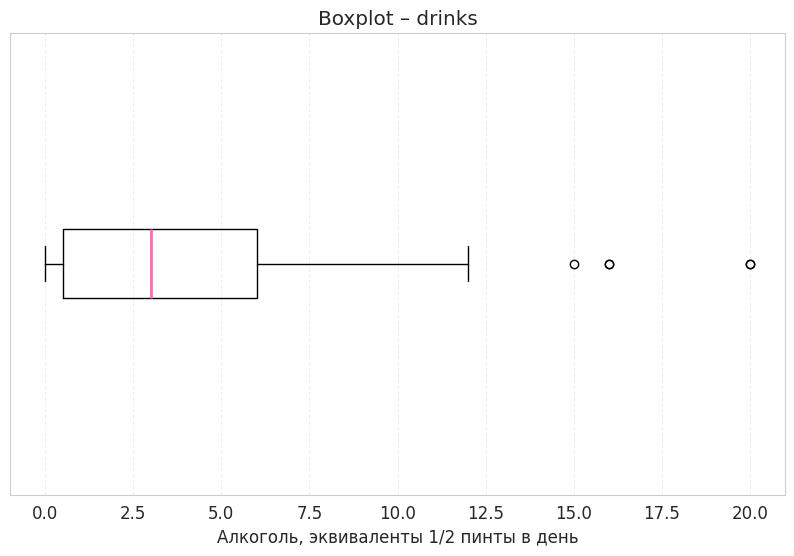

In [ ]:
# @title
plt.boxplot(drinks, vert=False, medianprops={'color': 'hotpink', 'linewidth': 2})
plt.xlabel("Алкоголь, эквиваленты 1/2 пинты в день")
plt.title("Boxplot – drinks")
plt.grid(alpha=0.3, linestyle='--')
plt.yticks([])
plt.show()

> — Вот он розовый ящик — центральные 50% жителей. Розовая линия внутри — медиана
>
> Юноша прищурился:
>
> — А справа выбросы. Те самые ходячие пивоварни.
>
> — Подождите, друзья... Давайте зафиксируем всё в нашем блокноте. — сказал Старец и достал перо.








In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Интерпретация описательной статистики</h3>

    <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
        В выборке из 345 пациентов:
    </p>

    <ul style="font-size: 15px; color: #333; line-height: 1.8; list-style-type: none; padding-left: 0; margin-bottom: 20px;">
        <li style="margin-bottom: 12px;">
            <b>Среднее потребление</b> составило 3.46, медиана - 3.0. Среднее превышает медиану, что указывает на правостороннюю асимметрию распределения.
        </li>
        <li style="margin-bottom: 12px;">
            <b>Межквартильный размах</b> (IQR = Q₃ - Q₁ = 5.5) показывает, что центральные 50% пациентов употребляют от 0.5 до 6.0 порций в день.
        </li>
        <li style="margin-bottom: 12px;">
            <b>Разброс значений</b> огромный: от 0 до 20 порций в день. Это говорит о значительной неоднородности выборки.
        </li>
        <li style="margin-bottom: 12px;">
            <b>Коэффициент асимметрии</b> ~ 1.54 подтверждает выраженную правостороннюю асимметрию: большинство пациентов пьют умеренно, но есть небольшая группа с аномально высоким потреблением.
        </li>
    </ul>

    <div style="background-color: #fff0f5; padding: 18px; border-radius: 6px; border-left: 4px solid hotpink;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            <b>Вывод:</b> Распределение drinks не является симметричным и, скорее всего, не подчиняется нормальному закону.
        </p>
    </div>
</div>
""")

#### Распределение

>  — Прежде чем искать связи и проверять гипотезы, нужно понять природу наших данных, — сказал Старец.
>
> Он открыл учебник:
>
> — Для дискретной величины вероятность каждого значения — это число людей с этим уровнем потребления, делённое на общее количество. Видите формулы, перепишите их к себе в блокнот.
>
> — Уже записываю, — говорила первая девушка.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Распределение случайной величины X₁ = drinks</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">1. Эмпирическая вероятность</h4>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            P(X₁ = xⱼ) = nⱼ / N
        </div>

        <p style="font-size: 14px; color: #333; line-height: 1.6; margin: 0;">
            где nⱼ — число наблюдений с уровнем потребления xⱼ, N = 345 — общее количество жителей в выборке.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">2. Математическое ожидание</h4>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            E[X₁] = Σⱼ xⱼ · pⱼ
        </div>

        <p style="font-size: 14px; color: #333; line-height: 1.6; margin: 0;">
            где pⱼ = P(X₁ = xⱼ) — вероятность значения xⱼ.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">3. Дисперсия</h4>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            D[X₁] = Σⱼ (xⱼ − E[X₁])² · pⱼ
        </div>
    </div>
</div>
""")

> — Теперь посчитаем, сколько жителей пьёт каждую порцию, — сказала первая девушка.
>
> — Это функция массы вероятности (PMF). — ответил ей Старец.
Он запустил заклинание, и на зеркале появились розовые столбцы...


In [ ]:
# @title
drinks_pmf = drinks.value_counts().sort_index().rename("count").to_frame()
drinks_pmf["probability"] = drinks_pmf["count"] / len(drinks)
display(drinks_pmf)

x, y = ecdf_xy(drinks)

,count,probability
drinks,,
0.0000,9,0.0261
0.5000,108,0.3130
1.0000,17,0.0493
2.0000,35,0.1014
3.0000,21,0.0609
4.0000,50,0.1449
5.0000,17,0.0493
6.0000,40,0.1159
7.0000,6,0.0174


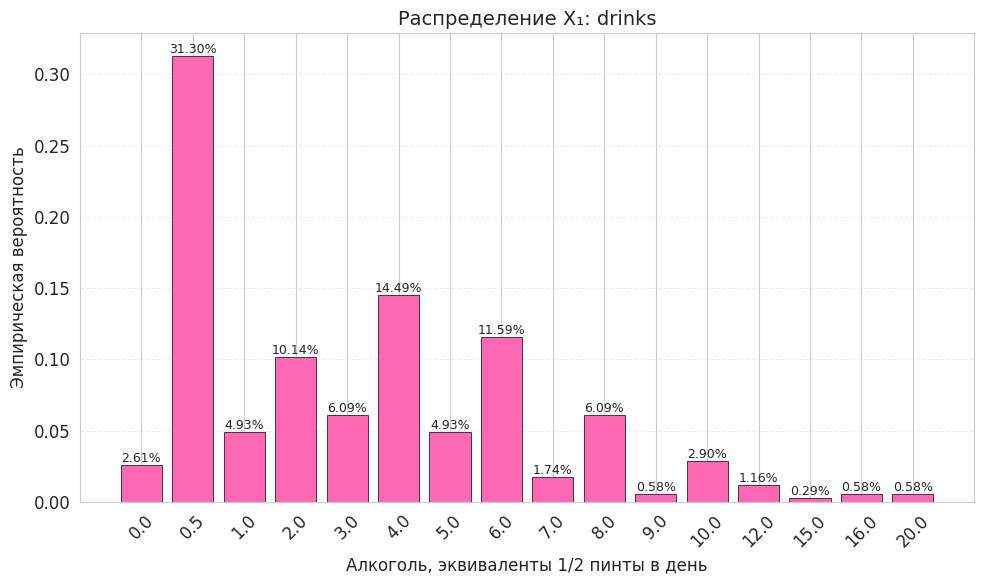

In [ ]:
# @title
pmf = drinks.value_counts(normalize=True).sort_index()

bars = plt.bar(pmf.index.astype(str), pmf.values,
               color='hotpink', edgecolor='black', linewidth=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2%}', ha='center', va='bottom', fontsize=9)

plt.xlabel("Алкоголь, эквиваленты 1/2 пинты в день")
plt.ylabel("Эмпирическая вероятность")
plt.title("Распределение X₁: drinks", fontsize=14)
plt.grid(axis="y", alpha=0.3, linestyle='--')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

> — Почти треть мужчин пьют всего по полпорции в день. — воскликнула первая девушка.
>
> Юноша проследил взглядом вправо:
— На четырёх и шести порциях вообще-то тоже пики.
>
> Но дальше столбцы становились всё ниже. На отметке двадцать стояли два редких жителя — видимо, те, кого исследователи уже прозвали ходячей пивоварней.
>
> — Но теперь другой вопрос: сколько людей пьёт не больше заданного количества? — с улыбкой смотрел на исследователей Старец.
>
> — Это эмпирическая функция распределения, — догадалась вторая девушка.

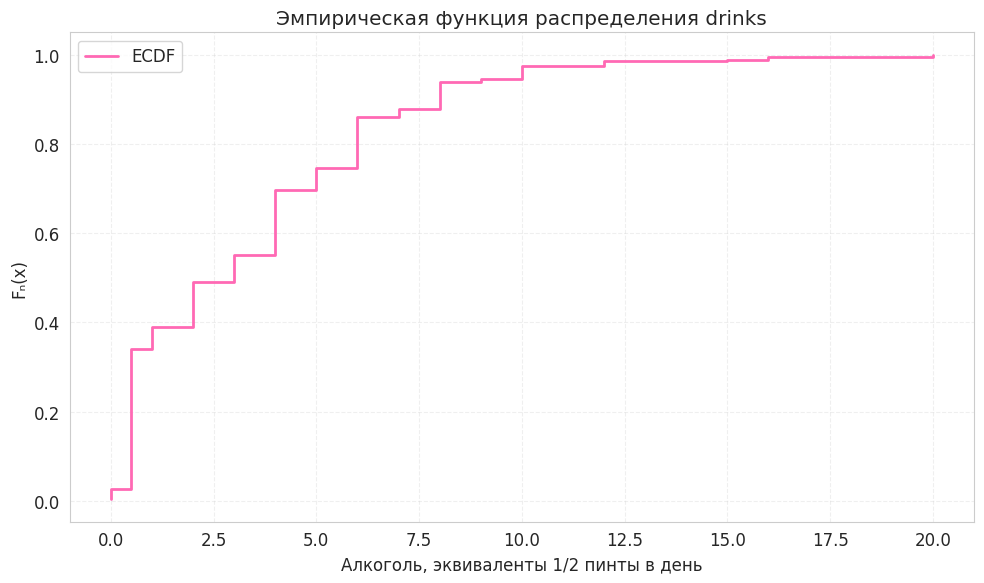

In [ ]:
# @title
plt.step(x, y, where="post", color='hotpink', linewidth=2, label='ECDF')
plt.xlabel("Алкоголь, эквиваленты 1/2 пинты в день")
plt.ylabel("Fₙ(x)")
plt.title("Эмпирическая функция распределения drinks")
plt.grid(alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

> — График взлетает почти вертикально в самом начале, — воскликнула первая девушка, указывая на зеркало.
>
> Старец кивнул:
> — Верно. Судя по графику половина жителей Королевства пьёт не больше двух с половиной порций в день.


### Гипотеза о нормальности

> — Мы уже видели, что распределение скошено вправо. Но формально это нужно доказать, — сказал Старец.
>
> — Нужен критерий. Давайте подберём нужный. — говорил юноша.
>
> Вторая девушка вдруг подняла голову:
>
> — А я знаю какой критерий нам подойдёт. Шапиро-Уилк! Он создан именно для таких случаев, как наш. Сейчас всё объясню.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 20px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">


    <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
        Мы должны выбрать критерий Шапиро–Уилка по трём причинам:
    </p>

    <ul style="font-size: 15px; color: #333; line-height: 1.6; list-style-type: none; padding-left: 0; margin-bottom: 20px;">
        <li style="margin-bottom: 10px;">
             <b>1) Оптимальность для объема:</b> При N = 345 этот тест считается самым подходящим. Он обладает наибольшей мощностью и лучше других замечает отклонения.
        </li>
        <li style="margin-bottom: 10px;">
             <b>2) Чувствительность к хвостам:</b> Биохимические данные часто имеют тяжелые хвосты. Шапиро–Уилк специально разработан так, чтобы реагировать на отклонения именно в хвостах распределения, где другие тесты могут быть менее чувствительны.
        </li>
        <li style="margin-bottom: 10px;">
             <b>3) Строгость:</b> В отличие от визуальной оценки гистограммы, тест дает объективную вероятность (<i>p-value</i>). Если p &lt; 0.05, мы можем с уверенностью отвергнуть гипотезу о нормальности.
        </li>
    </ul>
        </ul>
    </div>
</div>
""")

> Исследователи сформировали две гипотезы:

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Формальная проверка нормальности</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Гипотезы</h4>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-bottom: 15px;">
            <p style="font-size: 16px; color: #333; line-height: 1.8; margin: 0;">
                <b>H₀:</b> drinks имеет нормальное распределение.
            </p>
        </div>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
            <p style="font-size: 16px; color: #333; line-height: 1.8; margin: 0;">
                <b>H₁:</b> распределение drinks не является нормальным.
            </p>
        </div>
    </div>
</div>
""")

In [ ]:
shapiro_d = stats.shapiro(drinks)

print(f"Shapiro W = {shapiro_d.statistic:.6f}")
print(f"p-value = {shapiro_d.pvalue:.3e}")

Shapiro W = 0.835494
p-value = 1.686e-18


> — Значение p-value близко к нолю. Нулевая гипотеза отвергнута без всяких сомнений. — сказала первая девушка.
>
> Давайте посмотрим на Q-Q plot. Если точки лягут на прямую — распределение нормальное. Если отклонятся — значит, есть хвосты или асимметрия. — ответил ей юноша

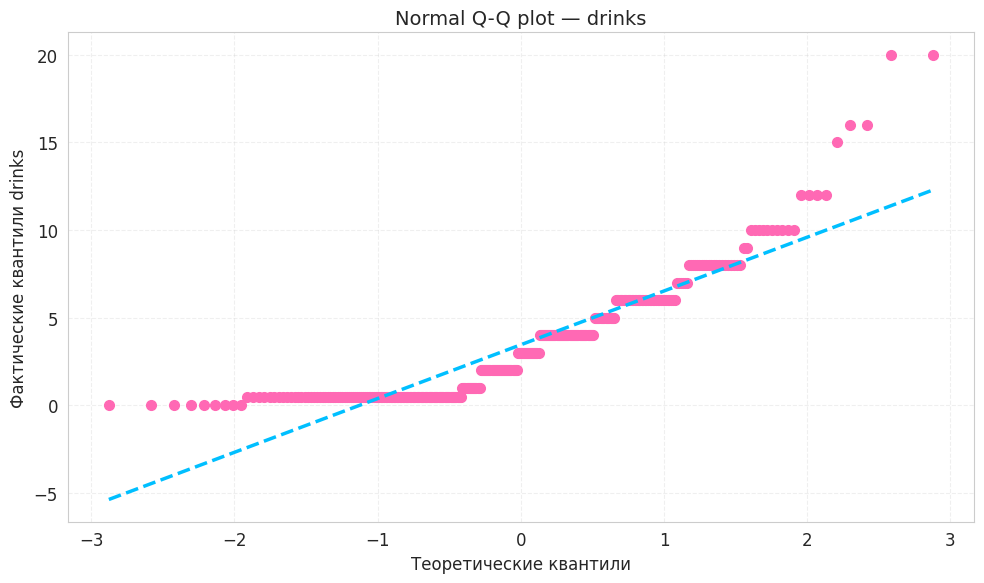

In [ ]:
# @title
fig, ax = plt.subplots(figsize=(10, 6))

stats.probplot(drinks, dist="norm", plot=ax)

lines = ax.get_lines()
lines[0].set_color('hotpink')
lines[0].set_marker('o')
lines[0].set_markersize(7)
lines[0].set_markeredgecolor('hotpink')
lines[0].set_markerfacecolor('hotpink')
lines[0].set_linestyle('None')

lines[1].set_color('deepskyblue')
lines[1].set_linewidth(2.5)
lines[1].set_linestyle('--')

ax.set_title("Normal Q-Q plot — drinks", fontsize=14)
ax.set_xlabel("Теоретические квантили")
ax.set_ylabel("Фактические квантили drinks")
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Точки совсем не ложаться на прямую! — воскликнула первая девушка.
>
> — Давайте опишем результаты в нашем блокноте. —  сказал Старец.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Результаты теста Шапиро–Уилка</h4>

        <div style="text-align: center; margin: 20px 0; font-size: 20px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            Shapiro W = 0.8354<br>
            p-value = 1.686 × 10⁻¹
        </div>
    </div>

    <div style="background-color: #fff0f5; padding: 18px; border-radius: 6px; border-left: 4px solid hotpink; margin-bottom: 20px;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            При уровне значимости α = 0.05 выполняется условие p-value ≪ α. Следовательно, нулевая гипотеза H₀ отвергается. Распределение <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">drinks</code> не является нормальным.
        </p>
    </div>
</div>
""")

### Математическая модель распределения

— Хммммм, мне кажется, что мы имеем дело с дискретной величиной — задумчиво воскликнул юноша, показывая на колонку `drinks`. — Да, точно, раз мы считаем счётные события (порции) за фиксированный интервал времени, то это же классическое распределение Пуассона! Хотя, конечно, крустно, что распределение не нормальное.

Старец покачал головой, поправляя очки:
— Не спеши с выводами. Распределение Пуассона требует строгого условия: математическое ожидание должно быть равно дисперсии. Но люди неоднородны: большинство пьют умеренно, но некоторые устраивают "праздники живота", превращаяс в "ходячие пивоварни". Это, в свою очередь, порождает сверхдисперсию, когда разброс данных значительно превышает среднее.

— О, я знаю, для таких случаев используется отрицательное биномиальное распределение — сказала одна из девушек — Оно является обобщением Пуассона и позволяет моделировать большие правые хвосты.

— Верно — сказал Старец — тогда посмотрим, что записано у меня в блокноте по этому поводу.


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Математическое обоснование</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">1. Распределение Пуассона</h4>
        <p style="font-size: 15px; color: #333; line-height: 1.8; margin: 0;">
            Пусть X ~ Pois(&#955;) — случайная величина, подчиняющаяся распределению Пуассона.
        </p>
        <div style="text-align: center; margin: 15px 0; font-size: 18px; font-family: 'Times New Roman', serif; color: #000;">
            P(X=k) = &#955;<sup>k</sup> · e<sup>-&#955;</sup> / k!
        </div>
        <p style="font-size: 15px; color: #333; line-height: 1.8; margin: 0;">
            где &#955; — параметр распределения, равный одновременно математическому ожиданию и дисперсии:
        </p>
        <div style="text-align: center; margin: 15px 0; font-size: 17px; font-family: 'Times New Roman', serif; color: #000;">
            E[X] = Var(X) = &#955;
        </div>
        <div style="background-color: #fff0f5; padding: 12px 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-top: 15px;">
            <p style="font-size: 14px; color: #333; line-height: 1.6; margin: 0;">
                <b>Ограничение:</b> Распределение Пуассона требует строгого равенства среднего и дисперсии. Если данные показывают сверхдисперсию (Var(X) > E[X]), модель Пуассона недостаточна.
            </p>
        </div>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">2. Отрицательное биномиальное распределение</h4>
        <p style="font-size: 15px; color: #333; line-height: 1.8; margin: 0;">
            Пусть X ~ NB(r, p) — случайная величина, подчиняющаяся отрицательному биномиальному распределению.
        </p>
        <div style="text-align: center; margin: 15px 0; font-size: 18px; font-family: 'Times New Roman', serif; color: #000;">
            P(X=k) = C(k+r-1, k) · (1-p)<sup>r</sup> · p<sup>k</sup>
        </div>
        <p style="font-size: 15px; color: #333; line-height: 1.8; margin: 0;">
            где r > 0 — параметр формы, p &#8712; (0, 1) — вероятность "успеха".
        </p>
        <p style="font-size: 15px; color: #333; line-height: 1.8; margin: 15px 0 0 0;">
            <b>Моменты распределения:</b>
        </p>
        <div style="text-align: center; margin: 15px 0; font-size: 17px; font-family: 'Times New Roman', serif; color: #000;">
            E[X] = r(1-p)/p, &nbsp;&nbsp;&nbsp; Var(X) = r(1-p)/p&#178;
        </div>
        <div style="background-color: #fff0f5; padding: 12px 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-top: 15px;">
            <p style="font-size: 14px; color: #333; line-height: 1.6; margin: 0;">
                <b>Ключевое свойство:</b> Очевидно, что Var(X) > E[X] при любых допустимых параметрах. Это делает отрицательное биномиальное распределение идеальным инструментом для моделирования данных со сверхдисперсией.
            </p>
        </div>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">3. Метод подбора параметров (метод моментов)</h4>
        <p style="font-size: 15px; color: #333; line-height: 1.8; margin: 0;">
            Для оценки параметров r и p используем метод моментов, приравнивая теоретические моменты к выборочным (x&#772; и s&#178;):
        </p>
        <div style="text-align: center; margin: 15px 0; font-size: 17px; font-family: 'Times New Roman', serif; color: #000;">
            p = x&#772; / s&#178;, &nbsp;&nbsp;&nbsp; r = x&#772;&#178; / (s&#178; - x&#772;)
        </div>
        <div style="background-color: #fff0f5; padding: 12px 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-top: 15px;">
            <p style="font-size: 14px; color: #333; line-height: 1.6; margin: 0;">
                <b>Условие применимости:</b> Формулы корректны только при s&#178; > x&#772; (сверхдисперсия). Если s&#178; &#8804; x&#772;, модель вырождается в распределение Пуассона.
            </p>
        </div>
    </div>

</div>
""")

— Так, попробуем-ка воплотить эту модель на наших волшебных зеркалах! — сказал юноша

In [ ]:
# @title
x_emp = np.sort(drinks.unique())
emp_pmf = [np.mean(drinks == x) for x in x_emp]

mean_x = drinks.mean()
var_x = drinks.var(ddof=1)

print(f"Эмпирическое среднее (x̄): {mean_x:.4f}")
print(f"Эмпирическая дисперсия (s²): {var_x:.4f}")
print(f"Отношение Дисперсия / Среднее: {var_x / mean_x:.4f}")

if var_x > mean_x:
    print("Var > Mean. Отрицательное биномиальное распределение применимо.")
else:
    print("Сверхдисперсия не обнаружена. Отрицательное биномиальное распределение не применимо.")


Эмпирическое среднее (x̄): 3.4551
Эмпирическая дисперсия (s²): 11.1411
Отношение Дисперсия / Среднее: 3.2246
Var > Mean. Отрицательное биномиальное распределение применимо.


— Всё как сказал Старец — сказала одна их юных дев — отрицательное биномиальное распределение нам подходит, поскольку мы имеем свердисперсию. Тогда оценим параметры методом моментов.

In [ ]:
# @title
p_nb = mean_x / var_x
r_nb = (mean_x**2) / (var_x - mean_x)

print(f"   p = {p_nb:.4f}")
print(f"   r = {r_nb:.4f}")

   p = 0.3101
   r = 1.5531


— Отлично, параметры оценены, — сказала вторая девушка — Теперь нужно сравнить, насколько хорошо наше распределение описывает данные по сравнению с Пуассоном.

— Для этого посчитаем сумму квадратов ошибок между эмпирической и теоретической функциями вероятностей, — добавил Старец — Меньшее значение SSE укажет на более подходящую модель.

In [ ]:
# @title
nbinom_pmf = [stats.nbinom.pmf(x, r_nb, p_nb) for x in x_emp]
poisson_pmf = [stats.poisson.pmf(x, mean_x) for x in x_emp]

sse_nbinom = np.sum((np.array(emp_pmf) - np.array(nbinom_pmf))**2)
sse_poisson = np.sum((np.array(emp_pmf) - np.array(poisson_pmf))**2)

print(f"Ошибка аппроксимации:")
print(f"   Пуассон: {sse_poisson:.6f}")
print(f"   Отрицательное биномиальное: {sse_nbinom:.6f}")

best_model = "Отрицательное биномиальное" if sse_nbinom < sse_poisson else "Пуассона"
print(f"\nВывод: Наилучшую аппроксимацию дает распределение {best_model}.")

Ошибка аппроксимации:
   Пуассон: 0.146907
   Отрицательное биномиальное: 0.147225

Вывод: Наилучшую аппроксимацию дает распределение Пуассона.


— Опачки! — сказал юноша — Выходит, что распределение Пауссона подходит для наших данных лучше? А как-же сверхдисперсия, о мудрый Старец?!

Старец ответил:

— Да, бывает и такое. Более простая модель с одним параметром справилась с нашими данными ничуть не хуже модели с двумя параметрами. В данном случае мы воспользуемся принципом бритвы Оккама - из двух моделей со схожим качеством мы выбираем более простую. Но про сверхдисперсию я помню, так что давайте визуализируем обе модели и сделаем вывод.

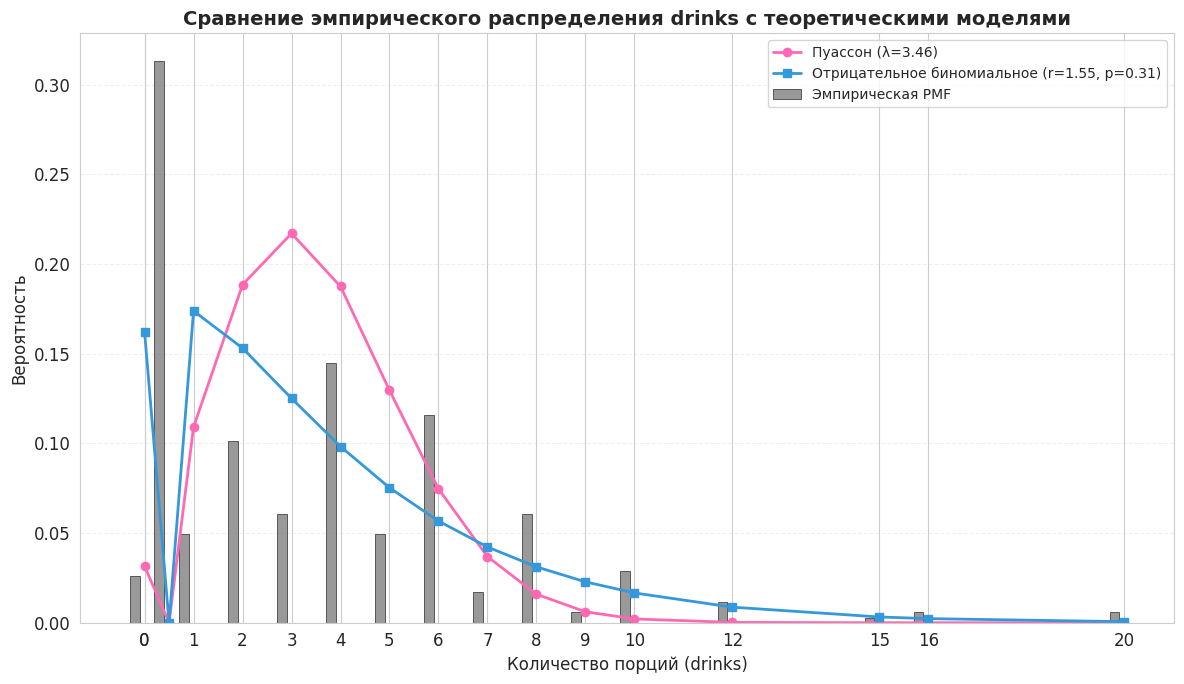

In [ ]:
# @title
plt.figure(figsize=(12, 7))
width = 0.2

# Эмпирические данные - серые бары
plt.bar(x_emp - width, emp_pmf, width, label='Эмпирическая PMF', color='#808080', alpha=0.8, edgecolor='black', linewidth=0.5)

# Теоретические распределения - линии с маркерами
plt.plot(x_emp, poisson_pmf, 'o-', color='hotpink', linewidth=2, markersize=6, label=f'Пуассон (λ={mean_x:.2f})')
plt.plot(x_emp, nbinom_pmf, 's-', color='#3498db', linewidth=2, markersize=6, label=f'Отрицательное биномиальное (r={r_nb:.2f}, p={p_nb:.2f})')

plt.xlabel('Количество порций (drinks)', fontsize=12)
plt.ylabel('Вероятность', fontsize=12)
plt.title('Сравнение эмпирического распределения drinks с теоретическими моделями', fontsize=14, fontweight='bold')
plt.xticks(x_emp.astype(int))
plt.legend(loc='upper right', fontsize=10)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Вывод по математической модели</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Сравнение моделей</h4>

        <table style="width: 100%; border-collapse: collapse; font-size: 15px;">
            <tr style="background-color: #ffe6f0;">
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: left; color: #000;">Модель</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">Параметры</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">SSE</th>
            </tr>
            <tr>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Распределение Пуассона</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">&#955; = 3.46</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">0.146907</td>
            </tr>
            <tr style="background-color: #fff9e6;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Отрицательное биномиальное</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">r = 1.55, p = 0.31</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">0.147225</td>
            </tr>
        </table>

        <p style="font-size: 14px; color: #555; line-height: 1.5; margin: 15px 0 0 0; font-style: italic;">
            Несмотря на наличие сверхдисперсии (Var/Mean = 3.22), распределение Пуассона показывает меньшую ошибку аппроксимации.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Принцип бритвы Оккама</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.8; margin: 0;">
            Если две модели показывают сопоставимое качество описания данных, следует выбирать более простую. В нашем случае:
        </p>

        <div style="background-color: #fff0f5; padding: 12px 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-top: 15px;">
            <p style="font-size: 14px; color: #333; line-height: 1.6; margin: 0;">
                Пуассон имеет 1 параметр (&#955;) и SSE = 0.146907.<br>
                Negative Binomial имеет 2 параметра (r, p) и SSE = 0.147225.<br><br>
                Более простая модель показывает лучший результат по критерию SSE.
            </p>
        </div>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Итог</h4>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
            <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
                <b>Выбранная модель:</b> Распределение Пуассона с параметром &#955; = 3.46.<br><br>
                <b>Обоснование:</b> Распределение Пуассона является достаточной и наиболее простой моделью для описания дискретной случайной величины <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">drinks</code>. Оно будет использовано в качестве основы для генератора случайных чисел во втором спринте.
            </p>
        </div>
    </div>

</div>
""")

Модель,Параметры,SSE
Распределение Пуассона,λ = 3.46,0.146907
Отрицательное биномиальное,"r = 1.55, p = 0.31",0.147225


### Нормализация / Стандартизация

> — Теперь нужно привести наш парметр к всемирному языку, чтобы потом мы смогли сравнить три величины между собой  —  размышлял юноша.
>
>  — У меня есть для вас два заклинания, которые я выкрал из академии в своё время  — хитро улыбался Старец.
>
>  —  Скорее запишите их в блокнот! - воскликнул юноша.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Нормализация и стандартизация</h3>
    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">1. Z-стандартизация</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Каждое значение переводится в количество стандартных отклонений от среднего:
        </p>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            Zᵢ = (Xᵢ − X̄) / s
        </div>

        <p style="font-size: 14px; color: #555; line-height: 1.6; margin: 0;">
            где X̄ — выборочное среднее, s — выборочное стандартное отклонение.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">2. Min-Max нормализация</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Все значения сжимаются в интервал [0, 1]:
        </p>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            X'ᵢ = (Xᵢ − X_min) / (X_max − X_min)
        </div>

        <p style="font-size: 14px; color: #555; line-height: 1.6; margin: 0;">
            где X_min и X_max — минимальное и максимальное значения в выборке.
        </p>
    </div>
</div>
""")

In [ ]:
# @title
drinks_z = z_standardize(drinks)
drinks_mm = minmax_normalize(drinks)

display(pd.DataFrame({
    "original": drinks,
    "z_score": drinks_z,
    "minmax": drinks_mm
}).head(10))

print("Z mean:", round(drinks_z.mean(), 10))
print("Z std:", round(drinks_z.std(ddof=1), 10))
print("Min-Max range:", drinks_mm.min(), drinks_mm.max())

,original,z_score,minmax
0,0.0000,-1.0351,0.0000
1,0.0000,-1.0351,0.0000
2,0.0000,-1.0351,0.0000
3,0.0000,-1.0351,0.0000
4,0.0000,-1.0351,0.0000
5,0.0000,-1.0351,0.0000
6,0.5000,-0.8853,0.0250
7,0.5000,-0.8853,0.0250
8,0.5000,-0.8853,0.0250
9,0.5000,-0.8853,0.0250


Z mean: 0.0
Z std: 1.0
Min-Max range: 0.0 1.0


> — Давайте посмотрим, как заклинание изменило данные, — сказала первая девушка. — Наложим старую и новую гистограммы друг на друга.


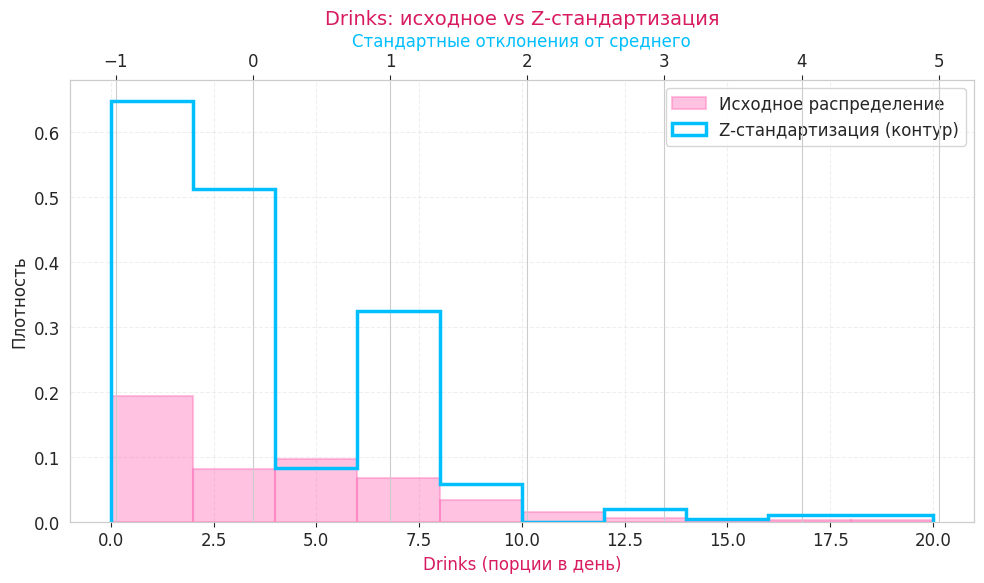

До: mean = 3.4551, std = 3.3378
После Z: mean = 0.0000000000, std = 1.0000000000


In [ ]:
# @title
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.hist(drinks, bins='sturges', density=True,
         color='hotpink', alpha=0.4, edgecolor='hotpink', linewidth=1.5,
         label='Исходное распределение')
ax2 = ax1.twiny()
ax2.hist(drinks_z, bins='sturges', density=True,
         histtype='step', color='deepskyblue', linewidth=2.5,
         label='Z-стандартизация (контур)')

ax1.set_xlabel('Drinks (порции в день)', fontsize=12, color='#d81b60')
ax2.set_xlabel('Стандартные отклонения от среднего', fontsize=12, color='deepskyblue')
ax1.set_ylabel('Плотность', fontsize=12)
ax1.set_title('Drinks: исходное vs Z-стандартизация', fontsize=14, color='#d81b60')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

ax1.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

print(f"До: mean = {drinks.mean():.4f}, std = {drinks.std(ddof=1):.4f}")
print(f"После Z: mean = {drinks_z.mean():.10f}, std = {drinks_z.std(ddof=1):.10f}")

> — Смотрите, — сказала первая девушка, — форма осталась точно такой же. Но ось X теперь другая. Вместо порций — стандартные отклонения.
>
> — Именно, — кивнул Старец. — Заклинание Z-стандартизации не меняет форму распределения. Оно лишь сдвигает центр в ноль и масштабирует разброс к единице. Асимметрия, выбросы, хвосты — всё остаётся на месте.


### Независимость и оценки

> — Теперь, мы должны понять, чем отличается всё Королевство от его малой части. — сказал Старец. — Все 345 жителей — это генеральная совокупность. Полная картина. Но в реальной жизни редко удаётся опросить каждого. Чаще приходится довольствоваться малой группой.
>
> — Но как понять какую именно выборку нам взять? 10, 50, 100 или вообще 300 человек — возмущался юноша
>
> — Мы возьмём выборку 100 человек, дайте мне блокнот, я объясню почему так — с добротой отчвечал Старец.

In [ ]:
# @title

from IPython.display import HTML

HTML("""
    <div style="background-color: #fff9e6; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Почему выбран объём выборки n = 100?</h4>

        <ul style="font-size: 15px; color: #333; line-height: 1.7; list-style-type: none; padding-left: 0; margin-bottom: 15px;">
            <li style="margin-bottom: 10px;">
                Выборка в 100 человек составляет около 30% от общей совокупности. Это типичный размер для многих медицинских исследований, где полный охват невозможен.
            </li>
            <li style="margin-bottom: 10px;">
                n = 100 достаточно велико, чтобы быть полезным, но достаточно мало, чтобы наглядно продемонстрировать наличие выборочной ошибки.
            </li>
            <li style="margin-bottom: 10px;">
                 При n ≥ 30  выборочное распределение среднего начинает приближаться к нормальному, даже если исходные данные сильно скошены. Это делает оценки более стабильными.
            </li>
        </ul>
    </div>
</div>
""")

> Юноша нахмурился:
> — А как именно брать эту сотню? Можно же одного и того же жителя опросить дважды...
>
> — Есть два способа. Первый — выборка без возвращения: каждого жителя можно взять только один раз. Второй — выборка с возвращением: один и тот же житель может попасть в группу несколько раз.


In [ ]:
# @title
import pandas as pd

pop_mean = drinks.mean()
pop_median = drinks.median()
pop_var = drinks.var()
pop_q1 = drinks.quantile(0.25)
pop_q3 = drinks.quantile(0.75)

sw_mean = sample_without["drinks"].mean()
sw_median = sample_without["drinks"].median()
sw_var = sample_without["drinks"].var()
sw_q1 = sample_without["drinks"].quantile(0.25)
sw_q3 = sample_without["drinks"].quantile(0.75)

sr_mean = sample_with["drinks"].mean()
sr_median = sample_with["drinks"].median()
sr_var = sample_with["drinks"].var()
sr_q1 = sample_with["drinks"].quantile(0.25)
sr_q3 = sample_with["drinks"].quantile(0.75)
n_unique_with = len(np.unique(idx_with))
n_unique_without = len(np.unique(idx_without))

col_without = f"Без возвращения (n={n_unique_without})"
col_with = f"С возвращением (n=100, {n_unique_with} уникальных)"

comparison = pd.DataFrame({
    "Статистика": ["mean", "median", "variance", "Q1", "Q3"],
    "Популяция (N=345)": [round(pop_mean, 4), round(pop_median, 4), round(pop_var, 4), round(pop_q1, 4), round(pop_q3, 4)],
    col_without: [round(sw_mean, 4), round(sw_median, 4), round(sw_var, 4), round(sw_q1, 4), round(sw_q3, 4)],
    col_with: [round(sr_mean, 4), round(sr_median, 4), round(sr_var, 4), round(sr_q1, 4), round(sr_q3, 4)],
    "Ошибка без возвр.": [round(abs(sw_mean - pop_mean), 4),
                          round(abs(sw_median - pop_median), 4),
                          round(abs(sw_var - pop_var), 4),
                          round(abs(sw_q1 - pop_q1), 4),
                          round(abs(sw_q3 - pop_q3), 4)],
    "Ошибка с возвр.": [round(abs(sr_mean - pop_mean), 4),
                        round(abs(sr_median - pop_median), 4),
                        round(abs(sr_var - pop_var), 4),
                        round(abs(sr_q1 - pop_q1), 4),
                        round(abs(sr_q3 - pop_q3), 4)]
})

display(comparison)

,Статистика,Популяция (N=345),Без возвращения (n=100),"С возвращением (n=100, 89 уникальных)",Ошибка без возвр.,Ошибка с возвр.
0,mean,3.4551,3.6900,3.5850,0.2349,0.1299
1,median,3.0000,3.0000,3.0000,0.0000,0.0000
2,variance,11.1411,15.8827,11.7427,4.7416,0.6016
3,Q1,0.5000,0.5000,0.5000,0.0000,0.0000
4,Q3,6.0000,5.0000,6.0000,1.0000,0.0000


> — При выборке без возвращения все 100 жителей уникальны, а с возвращением — всего 89, — отметила первая девушка.
>
> Вторая уже изучала таблицу:
> — Медиана — ровно 3, как у всей популяции. Q1 совпал идеально в обеих выборках. Среднее отличается на 0.23 без возвращения и на 0.13 с возвращением.
>
> — Малое зеркало честно отражает Королевство! — уверенно заявил юноша.
>
> — А если взять выборку поменьше? Скажем, 20 человек? — спросил он. — Тоже будет хорошо отражать?
>
> Старец улыбнулся: — Отличный вопрос. Ответ даёт понятие состоятельности оценки. Возьмите выборки разного размера, посчитайте среднее и дисперсию, и посмотрите, как они отличаются от истинных значений.
>
> Исследователи переглянулись и взялись за перья.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Состоятельность оценок</h3>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Оценка θ̂ₙ называется состоятельной, если при росте объёма выборки n она сходится по вероятности к истинному параметру θ:
        </p>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            θ̂ₙ → θ  (по вероятности, при n → ∞)
        </div>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Это означает, что чем больше данных мы собираем, тем ближе наша оценка к истинному значению параметра генеральной совокупности.
        </p>
    </div>
    <div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Эмпирическая проверка</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Для проверки состоятельности мы многократно строим выборки увеличивающегося объёма и для каждой считаем среднюю абсолютную ошибку (MAE) относительно параметров полной конечной совокупности:
        </p>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-bottom: 15px;">
            <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
                <b>MAE_mean</b> — средняя абсолютная ошибка выборочного среднего относительно истинного среднего популяции.
            </p>
        </div>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
            <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
                <b>MAE_variance</b> — средняя абсолютная ошибка выборочной дисперсии относительно истинной дисперсии популяции.
            </p>
        </div>
    </div>
</div>
""")

In [ ]:
# @title
cons_drinks = consistency_experiment(drinks)
display(cons_drinks)

,n,MAE_mean,MAE_variance
0,20,0.5858,4.3564
1,50,0.3545,2.8863
2,100,0.2219,1.7965
3,150,0.1601,1.2925
4,250,0.0901,0.7285
5,300,0.0541,0.4638


> — А теперь давайте визуализируем наши данные. — сказал Старец.
>
> Исследователи запустили заклинание и на волшебном зеркале начала рисоваться розовая кривая...

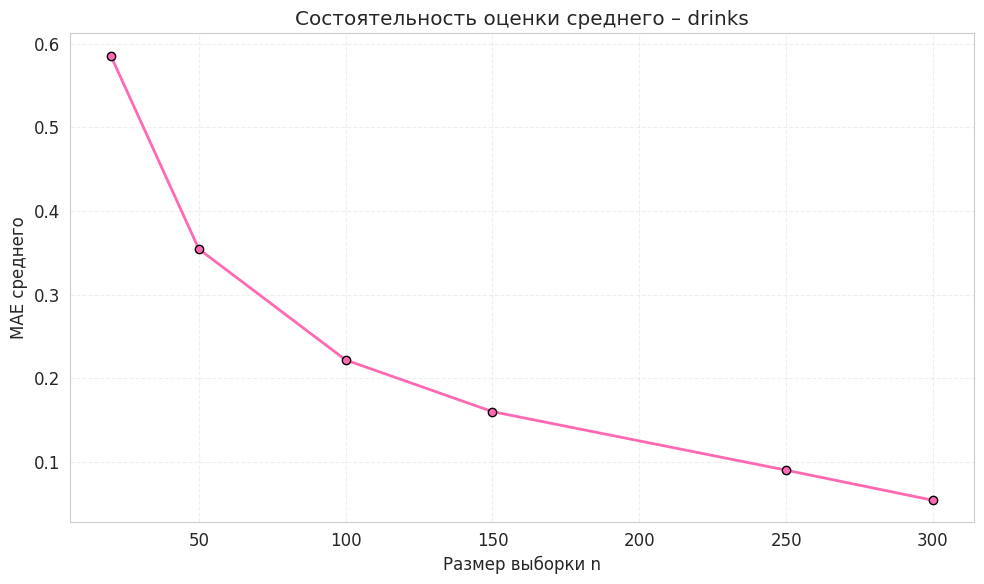

In [ ]:
# @title
cons_drinks = consistency_experiment(drinks)

plt.plot(cons_drinks["n"], cons_drinks["MAE_mean"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE среднего")
plt.title("Состоятельность оценки среднего – drinks")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Смотрите! — воскликнула первая девушка, тыча пером в зеркало. — Кривая плавно идёт вниз!
>
> — Это и есть состоятельность, — кивнул Старец.
>
> Исследователи записали в блокнот:


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
        MAE среднего монотонно убывает с ростом n, стремясь к нулю. Это эмпирическое подтверждение состоятельности выборочного среднего как оценки математического ожидания. Наибольший прирост точности достигается при переходе от малых выборок к средним.
        </p>
    </div>
</div>
""")

> — Теперь нужно проверить дисперсию. — сказала первая девушка.  

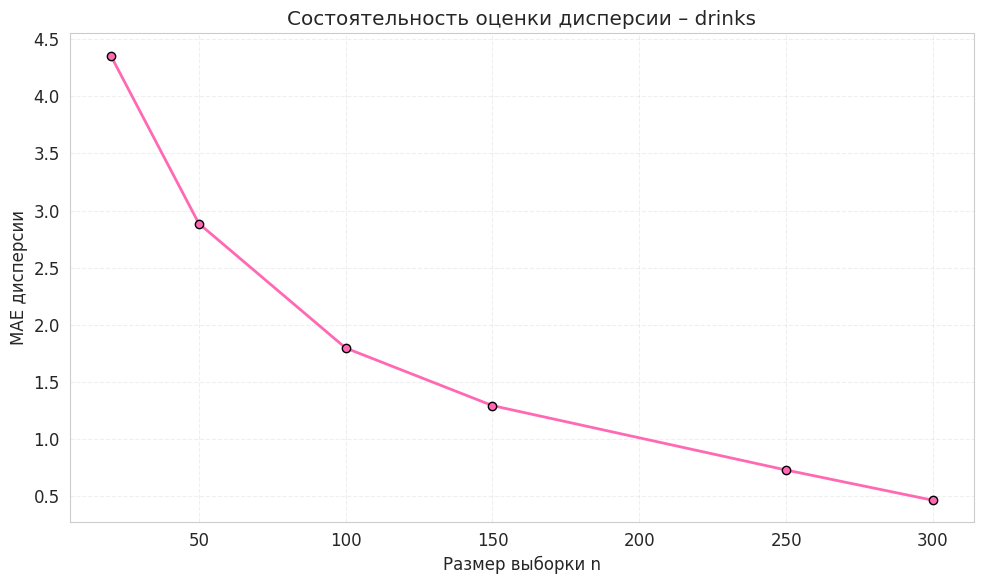

In [ ]:
# @title
plt.plot(cons_drinks["n"], cons_drinks["MAE_variance"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE дисперсии")
plt.title("Состоятельность оценки дисперсии – drinks")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Смотрите! Кривая снова идёт вниз! — воскликнула первая девушка.
>
> Вторая исследовательница записала в блокнот:


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
         MAE дисперсии монотонно убывает с ростом n, стремясь к нулю. Это эмпирическое подтверждение состоятельности выборочной дисперсии как оценки дисперсии генеральной совокупности. Как и в случае со средним, наибольший прирост точности достигается при переходе от малых выборок к средним.
        </p>
    </div>
</div>
""")

<a id="rv02"></a>
## Случайная величина 02 — Gamma-GT

> — Давайте разбираться со следующем параметром — `gammagt`.
>
> Исследовательница открыла новую страницу блокнота и записала:

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Вторая случайная величина</h3>

    <div style="text-align: center; margin: 25px 0; font-size: 24px; font-family: 'Times New Roman', serif; color: #000;">
        X₂(ω) = gammagt(ω)
    </div>
    <div style="background-color: #fff0f5; padding: 18px; border-radius: 6px; border-left: 4px solid hotpink;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Это случайная величина так как</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            При случайном выборе человека значение Gamma-GT заранее неизвестно — оно зависит от индивидуальных биологических показателей и не предсказывается никакой формулой.
        </p>
    </div>
</div>
""")

### EDA & распределение

#### EDA

> — Я помню, сначала описательная стаитистика, — говорила первая девушка.

In [ ]:
# @title
gammagt = df["gammagt"]
display(describe_rv(gammagt).to_frame("gammagt"))

,gammagt
n,345.0000
mean,38.2841
median,25.0000
variance_unbiased,1540.9249
std_unbiased,39.2546
min,5.0000
Q1,15.0000
Q3,46.0000
IQR,31.0000
max,297.0000


> — Давайте снова заглянем в волшебное зеркало, — сказал юноша.

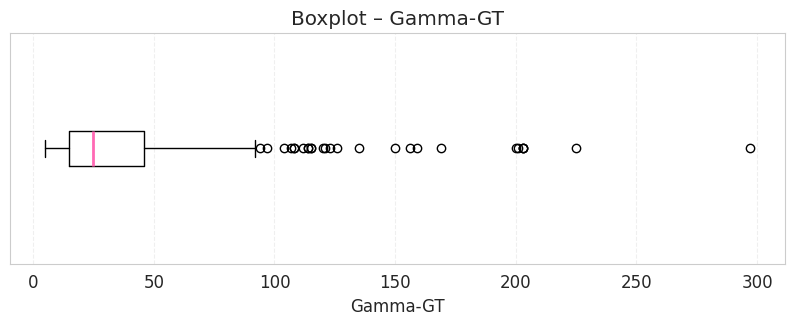

In [ ]:
# @title
plt.figure(figsize=(10, 3))
plt.boxplot(gammagt, vert=False, medianprops={'color': 'hotpink', 'linewidth': 2})
plt.xlabel("Gamma-GT")
plt.title("Boxplot – Gamma-GT")
plt.grid(alpha=0.3, linestyle='--')
plt.yticks([])
plt.show()

> — Я насчитал около двадцати кружочков... И один из них улетел аж до 300 — говорил юноша.
>
> Вторая исследовательница указала на ящик:
>
> — Смотрите, как он сжат влево. 75% жителей имеют Gamma-GT ниже 45.
>
> — Классическая картина биохимического показателя, — подытожил Старец. — Подавляющее большинство в норме, но длинный хвост и россыпь выбросов говорят о том, что у небольшой группы пациентов печень страдает.
>
> Исследователи записали в блокнот:

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Интерпретация описательной статистики</h3>

    <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
        В выборке из <b>345 пациентов</b>:
    </p>

    <ul style="font-size: 15px; color: #333; line-height: 1.8; list-style-type: none; padding-left: 0; margin-bottom: 20px;">
        <li style="margin-bottom: 12px;">
            <b>Среднее значение</b> составило 38.28, медиана — 25.0. Среднее значительно превышает медиану, что указывает на выраженную правостороннюю асимметрию распределения.
        </li>
        <li style="margin-bottom: 12px;">
            <b>Межквартильный размах</b> (IQR = Q₃ − Q₁ = 31) показывает, что центральные 50% пациентов имеют уровень Gamma-GT от 15 до 46 Ед/л.
        </li>
        <li style="margin-bottom: 12px;">
           <b>Разброс значений</b> огромный: от 2 до 297 Ед/л. Это говорит о значительной неоднородности выборки — есть пациенты с почти нормальными показателями и те, чьи значения превышают норму в десятки раз.
        </li>
        <li style="margin-bottom: 12px;">
           <b>Коэффициент асимметрии</b> ~ 2.87 подтверждает экстремальную правостороннюю асимметрию.
        </li>
    </ul>

    <div style="background-color: #fff0f5; padding: 18px; border-radius: 6px; border-left: 4px solid hotpink;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
          <b>Вывод:</b> Распределение <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">gammagt</code> не является симметричным и не подчиняется нормальному закону. Асимметрия здесь гораздо более выражена, чем у <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">drinks</code> (2.87 против 1.54), что характерно для биохимических показателей с тяжёлыми выбросами.
        </p>
    </div>
</div>
""")

#### Распределение

> — Давайте определим природу `Gamma-GT` — сказал Старец.
>
> — Нужно посмотреть, какие формулы нам лучше использовать, — сказал юноша и открыл учебник.
>
> Первая исследовательница записала всё в блокнот.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Распределение случайной величины X₂ = gammagt</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">1. Плотность вероятности</h4>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            P(a ≤ X₂ ≤ b) = ∫ₐᵇ f(x) dx
        </div>

        <p style="font-size: 14px; color: #555; line-height: 1.6; margin: 0;">
            где f(x) — плотность распределения, причём ∫₀^∞ f(x) dx = 1.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">2. Математическое ожидание</h4>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            X̄ = (1/n) · Σᵢ Xᵢ
        </div>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">3. Дисперсия</h4>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            S² = (1/(n−1)) · Σᵢ (Xᵢ − X̄)²
        </div>
    </div>
</div>
""")

> — Теперь запускаем заклинание гистограммы, — сказал юноша.
>
> На волшебном зеркале начали проступать розовые столбцы...

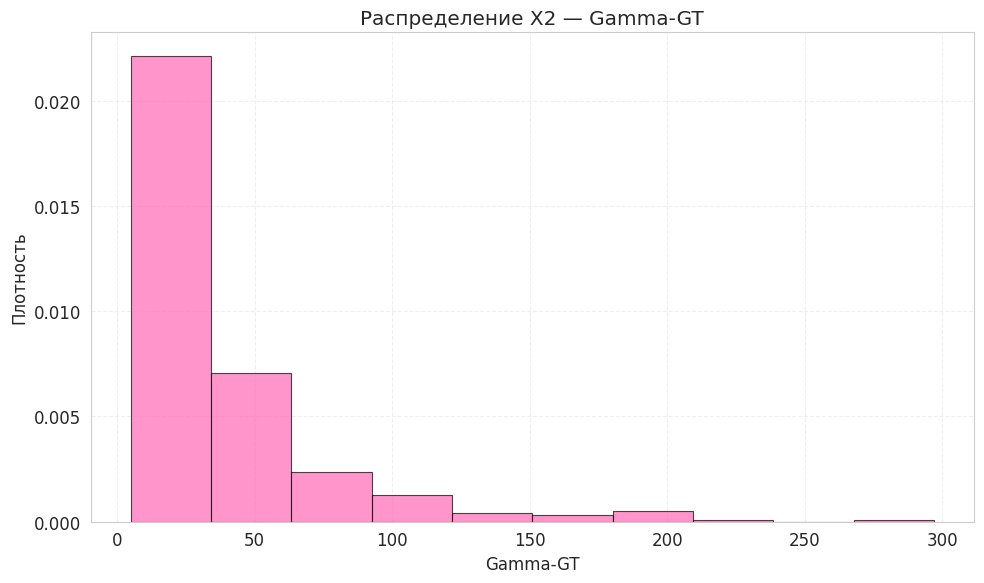

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(gammagt, bins="sturges", density=True,
         color='hotpink', edgecolor='black', linewidth=0.8, alpha=0.7)
plt.xlabel("Gamma-GT")
plt.ylabel("Плотность")
plt.title("Распределение X2 — Gamma-GT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Первый столбец поднялся почти до 0.023! — воскликнула первая девушка.
>
> Юноша прищурился:
> — То есть почти все жители имеют низкий Gamma-GT?
>
> — Именно, — подтвердил Старец. — Подавляющее большинство в диапазоне до 50 Ед/л.
>
> — Теперь используем ECDF. Мы уже использовали его для `drinks`, — сказал Старец.
>
> Исследователи запустили заклинание, и на зеркале начала рисоваться розовая кривая...


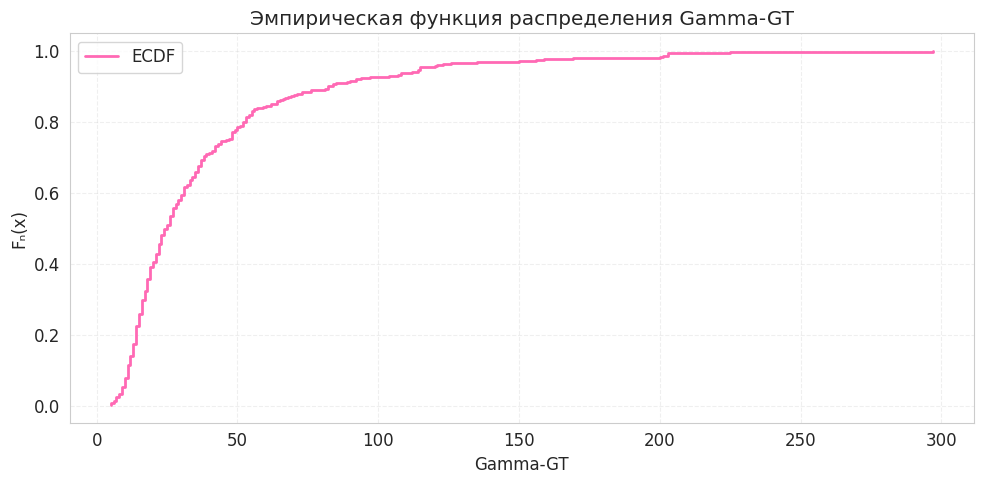

In [ ]:
# @title
x, y = ecdf_xy(gammagt)

plt.figure(figsize=(10, 5))
plt.step(x, y, where="post", color='hotpink', linewidth=2, label='ECDF')
plt.xlabel("Gamma-GT")
plt.ylabel("Fₙ(x)")
plt.title("Эмпирическая функция распределения Gamma-GT")
plt.grid(alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

> Юноша прищурился:
> — Уже к 50 Ед/л функция достигает 0.85. То есть 85% жителей имеют Gamma-GT ниже 50.
>
> Старец кивнул:
> — А к 100 — уже 95%. Оставшиеся 5% — это те самые больные люди с выбросами до 300.


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
          ECDF <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">gammagt</code> подтверждает экстремальную правостороннюю асимметрию. Подавляющее большинство значений сконцентрировано в начале (до 50 Ед/л), а длинный пологий хвост тянется до 300.
        </p>
    </div>
</div>
""")

### Гипотеза о нормальности

> — Теперь нужно доказать ненормальность `gammagt`, — сказал Старец.
>
> Используем то же заклинание, что и для `drinks`? Шапиро-Уилка? — спросил юноша.
>
> — Именно, — подтвердил Старец. — Он подходит, так как наш объём N = 345 остался таким же. Также, это заклинание чувствительно к тяжёлым хвостам, а у `gammagt` они до 300.
>
> — Запишем гипотезы в блокнот, — сказал юноша.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Формулировка гипотез для Gamma-GT</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Нулевая и альтернативная гипотезы</h4>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-bottom: 15px;">
            <p style="font-size: 16px; color: #333; line-height: 1.8; margin: 0;">
                <b>H₀:</b> <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">gammagt</code> имеет нормальное распределение.
            </p>
        </div>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
            <p style="font-size: 16px; color: #333; line-height: 1.8; margin: 0;">
                <b>H₁:</b> распределение <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">gammagt</code> не является нормальным.
            </p>
        </div>
    </div>
</div>
""")

In [ ]:
# @title
shapiro_g = stats.shapiro(gammagt)

print(f"Shapiro W = {shapiro_g.statistic:.6f}")
print(f"p-value = {shapiro_g.pvalue:.3e}")

Shapiro W = 0.683938
p-value = 6.481e-25


> — p-value равен 6.481 × 10⁻²⁵! — воскликнула первая девушка. —  Нулевая гипотеза отвергнута без всяких сомнений.

> Давайте посмотрим на Q-Q plot. Если точки лягут на прямую — распределение нормальное. Если отклонятся — значит, есть хвосты или асимметрия.

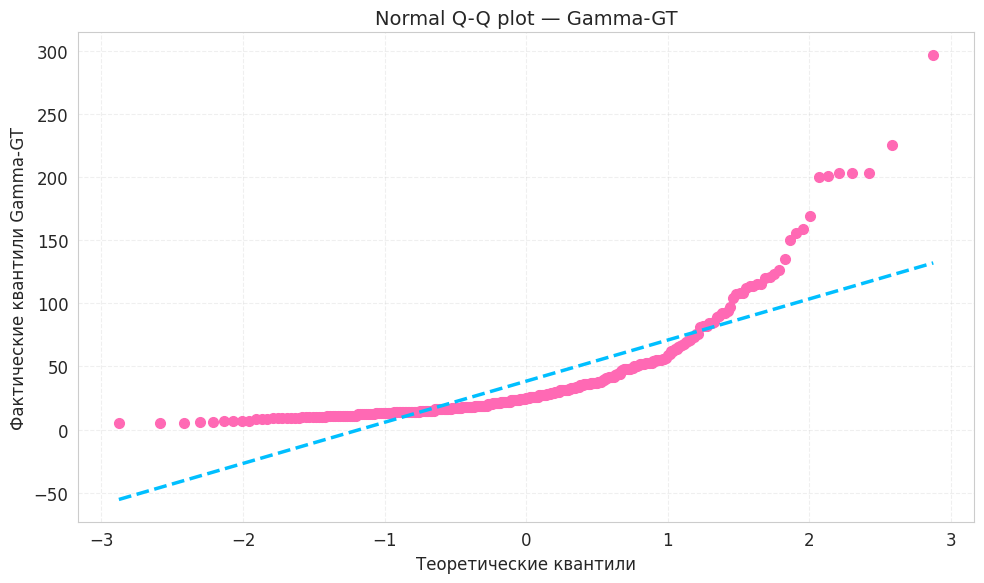

In [ ]:
# @title
fig, ax = plt.subplots(figsize=(10, 6))

stats.probplot(gammagt, dist="norm", plot=ax)

lines = ax.get_lines()
lines[0].set_color('hotpink')
lines[0].set_marker('o')
lines[0].set_markersize(7)
lines[0].set_markeredgecolor('hotpink')
lines[0].set_markerfacecolor('hotpink')
lines[0].set_linestyle('None')

lines[1].set_color('deepskyblue')
lines[1].set_linewidth(2.5)
lines[1].set_linestyle('--')

ax.set_title("Normal Q-Q plot — Gamma-GT", fontsize=14)
ax.set_xlabel("Теоретические квантили")
ax.set_ylabel("Фактические квантили Gamma-GT")
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Точки совсем не ложаться на прямую! — воскликнула первая девушка.
>
> — Давайте проверим одно логарифмическое преобразование для снижения выбросов: $Y=\ln(X_2)$. — сказал Старец, — и записал в блокнот:

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 20px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 17px;"> Логарифмическое преобразование</h4>

    <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
        Для положительных правосторонне-асимметричных данных применяется замена переменной:
    </p>

    <div style="text-align: center; margin: 20px 0; font-size: 20px; font-family: 'Times New Roman', serif; color: #000;">
        Y = ln(X)
    </div>

    <div style="background-color: white; padding: 15px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 15px;">
        <p style="font-size: 15px; color: #444; margin-top: 0; margin-bottom: 10px;">
            <b>Механизм воздействия:</b>
        </p>
        <ul style="font-size: 14px; color: #555; line-height: 1.6; list-style-type: none; padding-left: 0;">
            <li style="margin-bottom: 8px;">
                 <b>Сжатие больших значений:</b> поскольку производная функции ln(x) убывает (1/x), большие значения X сжимаются сильнее, чем малые. Это укорачивает длинный правый хвост распределения.
            </li>
            <li style="margin-bottom: 8px;">
                 <b>Растяжение малых значений:</b> значения вблизи нуля растягиваются, что увеличивает плотность наблюдений в левой части распределения.
            </li>
            <li style="margin-bottom: 8px;">
                 <b>Уменьшение асимметрии:</b> преобразование снижает коэффициент скошенности и эксцесс, приближая форму распределения к симметричной.
            </li>
        </ul>
    </div>

    <p style="font-size: 15px; color: #333; line-height: 1.6; margin-top: 0;">
        <b>Если после преобразования новая переменная Y подчиняется нормальному закону N(μ, σ²), то исходная величина X имеет логнормальное распределение.
    </p>
</div>
""")

In [ ]:
# @title
log_gammagt = np.log(gammagt)
print("Skewness original:", round(stats.skew(gammagt, bias=False), 4))
print("Skewness log:", round(stats.skew(log_gammagt, bias=False), 4))

Skewness original: 2.8661
Skewness log: 0.5169


In [ ]:
# @title
shapiro_log_g = stats.shapiro(log_gammagt)
print(f"Shapiro log W = {shapiro_log_g.statistic:.6f}")
print(f"Shapiro log p-value = {shapiro_log_g.pvalue:.3e}")

Shapiro log W = 0.977403
Shapiro log p-value = 3.072e-05


> — Ну что, — сказала первая девушка, разглядывая зеркало, — логарифм сжал хвост, но p-value всё ещё много меньше α = 0.05. Нулевая гипотеза снова отвергнута.


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 4px solid hotpink; padding: 12px 18px; border-radius: 6px; margin: 10px 0; box-shadow: 0 1px 3px rgba(0,0,0,0.04); font-family: sans-serif;">
    <p style="font-size: 15px; color: #333; line-height: 1.5; margin: 0;">
        Логарифмирование уменьшает асимметрию, однако точная нормальность также не достигается.
    </p>
</div>
""")

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">
    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Результаты теста Шапиро–Уилка</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Применён тест Шапиро–Уилка с уровнем значимости α = 0.05 дважды: для исходных данных и после логарифмического преобразования <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">Y = ln(X₂)</code>.
        </p>

        <table style="width: 100%; border-collapse: collapse; font-size: 15px; margin-bottom: 10px;">
            <tr style="background-color: #ffe6f0;">
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: left; color: #000;">Данные</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">Shapiro W</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">p-value</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">Решение</th>
            </tr>
            <tr>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;"><b>Исходные</b> <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">gammagt</code></td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">0.6839</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">6.481 × 10⁻²⁵</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #d81b60;"><b>H₀ отвергнута</b></td>
            </tr>
            <tr style="background-color: #fff9e6;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;"><b>После логарифмирования</b> <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">ln(gammagt)</code></td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">0.9774</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">3.072 × 10⁻⁵</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #d81b60;"><b>H₀ отвергнута</b></td>
            </tr>
        </table>
    </div>
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            <b>Интерпретация:</b> логарифмическое преобразование улучшило форму распределения — статистика W выросла с 0.684 до 0.977 (ближе к 1), асимметрия уменьшилась. Однако p-value = 3.072 × 10⁻⁵ всё ещё много меньше α = 0.05, поэтому нормальность формально не достигается.
        </p>
    </div>
</div>
""")

Данные,Shapiro W,p-value,Решение
Исходные gammagt,0.6839,6.481 × 10⁻²⁵,H₀ отвергнута
После логарифмирования ln(gammagt),0.9774,3.072 × 10⁻⁵,H₀ отвергнута


### Математическая модель распределения

> — А вдруг какое-то из распределений всё же ляжет хорошо на наши данные, — сказала одна из девушек, — давайте сравним нормальное, логнормальное, экспоненциальное, гамма — и посмотрим, кто из них лучше всего ложится на наши данные.
>
> — Почему бы и нет. Судить будет критерий Акаике, — добавил Старец.
> Исследователи переглянулись и взялись за перья. Впереди было испытание четырёх моделей.


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">


    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Кандидаты на роль модели распределения</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Выбраны четыре модели-кандидата:
        </p>

        <ul style="font-size: 15px; color: #333; line-height: 1.8; list-style-type: none; padding-left: 0; margin: 0;">
            <li style="margin-bottom: 8px;"><b>Normal</b> — классический колокол, симметричный и предсказуемый.</li>
            <li style="margin-bottom: 8px;"><b>Lognormal</b> — распределение, возникающее после логарифмирования правосторонне-асимметричных данных.</li>
            <li style="margin-bottom: 8px;"><b>Gamma</b> — гибкая модель, способная описывать данные с тяжёлым правым хвостом.</li>
            <li style="margin-bottom: 8px;"><b>Weibull</b> — заклинание из мира надёжности, привыкшее описывать время до события.</li>
        </ul>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Формула критерия Акаике</h4>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            AIC = 2k − 2 ln L
        </div>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 10px;">
            где:
        </p>

        <ul style="font-size: 15px; color: #333; line-height: 1.8; list-style-type: none; padding-left: 0; margin: 0;">
            <li style="margin-bottom: 8px;"><b>k</b> — число параметров модели.</li>
            <li style="margin-bottom: 8px;"><b>L</b> — максимизированное правдоподобие.</li>
        </ul>
    </div>

    <div style="background-color: #fff0f5; padding: 18px; border-radius: 6px; border-left: 4px solid hotpink; margin-bottom: 20px;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            <b>Главное правило:</b> чем меньше значение AIC, тем лучше модель.
        </p>
    </div>
</div>
""")

In [ ]:
# @title
fit_g, fitted_g = distribution_fit_table(gammagt)
display(fit_g)

,distribution,AIC,KS_statistic_descriptive,MLE_params
1,Lognormal,3094.0728,0.0703,"(0.7787867291737537, 0, 27.290735903010912)"
2,Gamma,3168.5895,0.1161,"(1.6238065666838846, 0, 23.576735527802224)"
3,Weibull,3192.4444,0.1175,"(1.187437894589408, 0, 40.998927670937654)"
0,Normal,3514.4138,0.2072,"(38.28405797101449, 39.1976841344471)"


> — Lognormal показывает себя лучше всех, а Normal — хуже всех, — сказал юноша.
>
> — Давайте проверим, как это заклинание ложится на реальные данные. — предложил Старец.

,distribution,AIC,KS_statistic_descriptive,MLE_params
1,Lognormal,3094.0728,0.0703,"(0.7787867291737537, 0, 27.290735903010912)"
2,Gamma,3168.5895,0.1161,"(1.6238065666838846, 0, 23.576735527802224)"
3,Weibull,3192.4444,0.1175,"(1.187437894589408, 0, 40.998927670937654)"
0,Normal,3514.4138,0.2072,"(38.28405797101449, 39.1976841344471)"


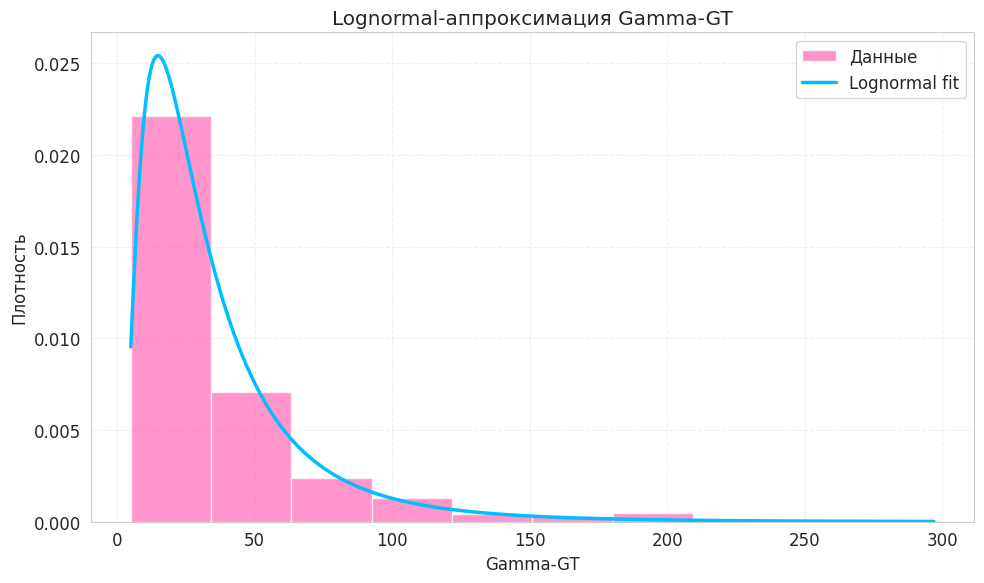

In [ ]:
# @title
table_g, fitted_g = distribution_fit_table(gammagt)
display(table_g)

grid = np.linspace(gammagt.min(), gammagt.max(), 600)

plt.figure(figsize=(10, 6))
plt.hist(gammagt, bins="sturges", density=True,
         color='hotpink', alpha=0.7, label="Данные")

dist_g, params_g = fitted_g["Lognormal"]
plt.plot(grid, dist_g.pdf(grid, *params_g),
         color='deepskyblue', linewidth=2.5, label="Lognormal fit")

plt.xlabel("Gamma-GT")
plt.ylabel("Плотность")
plt.title("Lognormal-аппроксимация Gamma-GT")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">
    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Таким образом, исследователи поняли, что наименьший AIC< получает <b>Lognormal</b>.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;"> Плотность логнормального распределения</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Если ln X ~ N(μ, σ²), то плотность логнормального распределения имеет вид:
        </p>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            f(x) = (1 / (xσ√(2π))) · exp( −(ln x − μ)² / (2σ²) ), &nbsp;&nbsp; x > 0
        </div>

        <p style="font-size: 14px; color: #555; line-height: 1.6; margin: 0;">
            где μ и σ — параметры нормального распределения логарифма величины.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Оценённые параметры</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            После подбора параметров по данным исследователи получили аппроксимацию:
        </p>

        <div style="text-align: center; margin: 20px 0; font-size: 22px; font-family: 'Times New Roman', serif; color: #000; background-color: #fff; padding: 15px; border-radius: 4px; border: 1px solid #e0e0e0;">
            μ ~ 3.31, &nbsp;&nbsp; σ ~ 0.78
        </div>
    </div>
</div>
""")

### Нормализация / Стандартизация

> — Теперь научим `gammagt` разговаривать на всемирном языке, сказала первая девушка — будем использовать те же заклинания, что и для  `drinks`

In [ ]:
# @title
g_z = z_standardize(gammagt)
print(f"Z mean: {g_z.mean():.10f}")
print(f"Z std:  {g_z.std(ddof=1):.10f}")

Z mean: 0.0000000000
Z std:  1.0000000000


In [ ]:
# @title
g_mm = minmax_normalize(gammagt)
print(f"Min-Max range: [{g_mm.min():.4f}, {g_mm.max():.4f}]")

Min-Max range: [0.0000, 1.0000]


> — Теперь посмотрим, как заклинание изменило данные, — сказал юноша.

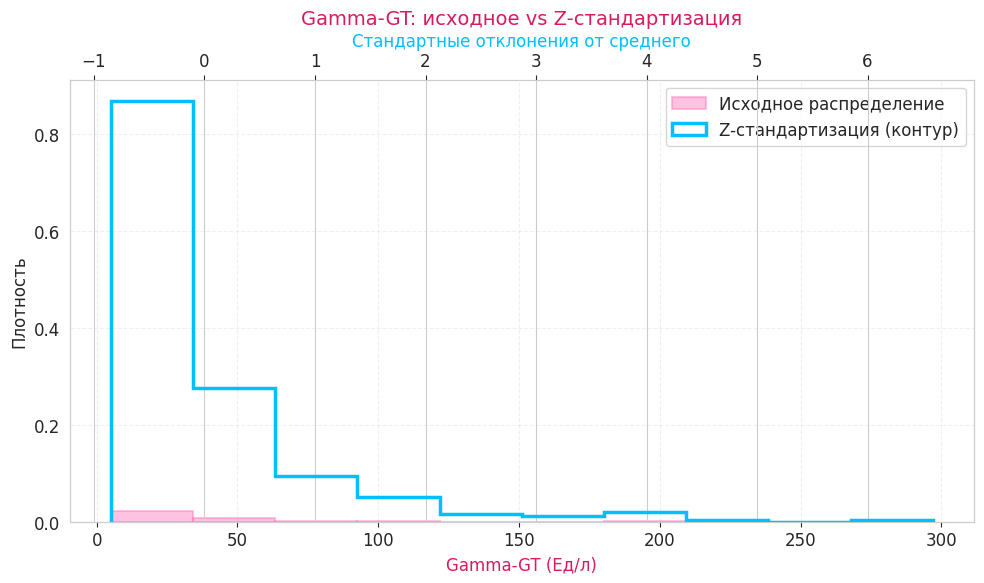

До: mean = 38.2841, std = 39.2546
После Z: mean = 0.0000000000, std = 1.0000000000


In [ ]:
# @title
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.hist(gammagt, bins='sturges', density=True,
         color='hotpink', alpha=0.4, edgecolor='hotpink', linewidth=1.5,
         label='Исходное распределение')

ax2 = ax1.twiny()
ax2.hist(g_z, bins='sturges', density=True,
         histtype='step', color='deepskyblue', linewidth=2.5,
         label='Z-стандартизация (контур)')

ax1.set_xlabel('Gamma-GT (Ед/л)', fontsize=12, color='#d81b60')
ax2.set_xlabel('Стандартные отклонения от среднего', fontsize=12, color='deepskyblue')
ax1.set_ylabel('Плотность', fontsize=12)
ax1.set_title('Gamma-GT: исходное vs Z-стандартизация', fontsize=14, color='#d81b60')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

ax1.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

print(f"До: mean = {gammagt.mean():.4f}, std = {gammagt.std(ddof=1):.4f}")
print(f"После Z: mean = {g_z.mean():.10f}, std = {g_z.std(ddof=1):.10f}")

> — Смотрите, — сказала первая девушка, — заклинание Z-стандартизации также не изменило форму. Всё работает отлично.


### Независимость и оценки

> — Мы уже убедились, что выборка из 100 жителей неплохо отражает `drinks`, — сказала первая девушка, — а будет ли эта выборка также хорошо отражать  `gammagt`?
>
> — Посчитаем mean, variance, median, Q1 и Q3 для всего Королевства и для выборки из 100 человек. Посмотрим, где расхождение больше. — сказал Старец

In [ ]:
# @title

import pandas as pd

pop_mean = gammagt.mean()
pop_median = gammagt.median()
pop_var = gammagt.var()
pop_q1 = gammagt.quantile(0.25)
pop_q3 = gammagt.quantile(0.75)

sw_mean = sample_without["gammagt"].mean()
sw_median = sample_without["gammagt"].median()
sw_var = sample_without["gammagt"].var()
sw_q1 = sample_without["gammagt"].quantile(0.25)
sw_q3 = sample_without["gammagt"].quantile(0.75)

sr_mean = sample_with["gammagt"].mean()
sr_median = sample_with["gammagt"].median()
sr_var = sample_with["gammagt"].var()
sr_q1 = sample_with["gammagt"].quantile(0.25)
sr_q3 = sample_with["gammagt"].quantile(0.75)

n_unique_with = len(np.unique(idx_with))
n_unique_without = len(np.unique(idx_without))

col_without = f"Без возвращения (n={n_unique_without})"
col_with = f"С возвращением (n=100, {n_unique_with} уникальных)"

comparison_g = pd.DataFrame({
    "Статистика": ["mean", "median", "variance", "Q1", "Q3"],
    "Популяция (N=345)": [round(pop_mean, 4), round(pop_median, 4), round(pop_var, 4), round(pop_q1, 4), round(pop_q3, 4)],
    col_without: [round(sw_mean, 4), round(sw_median, 4), round(sw_var, 4), round(sw_q1, 4), round(sw_q3, 4)],
    col_with: [round(sr_mean, 4), round(sr_median, 4), round(sr_var, 4), round(sr_q1, 4), round(sr_q3, 4)],
    "Ошибка без возвр.": [round(abs(sw_mean - pop_mean), 4),
                          round(abs(sw_median - pop_median), 4),
                          round(abs(sw_var - pop_var), 4),
                          round(abs(sw_q1 - pop_q1), 4),
                          round(abs(sw_q3 - pop_q3), 4)],
    "Ошибка с возвр.": [round(abs(sr_mean - pop_mean), 4),
                        round(abs(sr_median - pop_median), 4),
                        round(abs(sr_var - pop_var), 4),
                        round(abs(sr_q1 - pop_q1), 4),
                        round(abs(sr_q3 - pop_q3), 4)]
})

display(comparison_g)

,Статистика,Популяция (N=345),Без возвращения (n=100),"С возвращением (n=100, 89 уникальных)",Ошибка без возвр.,Ошибка с возвр.
0,mean,38.2841,40.4500,38.6000,2.1659,0.3159
1,median,25.0000,25.0000,26.0000,0.0000,1.0000
2,variance,1540.9249,1465.7652,1466.1010,75.1597,74.8239
3,Q1,15.0000,16.0000,15.0000,1.0000,0.0000
4,Q3,46.0000,53.5000,47.2500,7.5000,1.2500


> — Медиана совпала идеально в выборке без возвращения. А вот в выборке с возвращением ошибка 1.0, — сказала первая девушка.
>
> Юноша проследил взглядом вниз по таблице:
> — В выборке без возвращения ошибка 2.17, а с возвращением — всего 0.32. То есть выборка с возвращением оказалась точнее.
>
> — И дисперсия почти одинакова в обоих случаях, — заметила вторая девушка. — А вот Q1 совпал идеально в выборке с возвращением, а без возвращения — ошибка 1.0.
>
> — И Q3 — без возвращения ошибка 7.5. А с возвращением ошибка всего 1.25, — подытожил юноша. — Получается, для `gammagt` выборка с возвращением в этот раз отразила Королевство точнее, особенно по среднему и Q3.
>
> Исследовательницы записали в блокнот:
>
> — Теперь возьмём выборки ещё меньше, посчитаем среднее и дисперсию. В общем, всё будем делать также, как с `drinks`, — скомандовал юноша.


In [ ]:
# @title
cons_g = consistency_experiment(gammagt)
display(cons_g)

,n,MAE_mean,MAE_variance
0,20,7.0878,930.2019
1,50,4.0728,570.8540
2,100,2.5900,369.1726
3,150,2.0150,280.5196
4,250,1.0748,145.9534
5,300,0.6256,89.2471


> — Картина та же, что и для `drinks`, только цифры куда драматичнее, — сказал юноша. — При n = 20 ошибка среднего — целых 7.09! А ошибка дисперсии — 930. Маленькая группа из 20 человек почти не может оценить разброс биохимического показателя.
>
> — Это цена тяжёлых хвостов, — объяснил Старец. — Пока выборка мала, она не ловит выбросы под 300, и дисперсия сильно занижена. Чем больше жителей мы берём, тем точнее картина.

> — Давайте эмпирически подтвердим состоятельность выборочного среднего, — сказала девушка и запустила заклинание на зеркале.

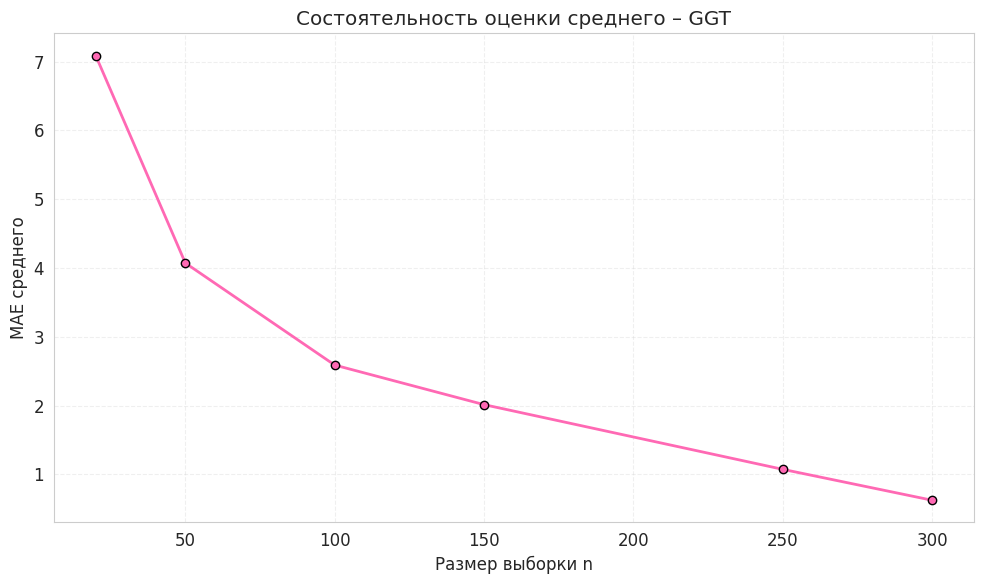

In [ ]:
# @title
cons_g = consistency_experiment(gammagt)

plt.figure(figsize=(10, 6))
plt.plot(cons_g["n"], cons_g["MAE_mean"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE среднего")
plt.title("Состоятельность оценки среднего – GGT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Смотрите, — кивнул Старец, — кривая неумолимо идёт вниз. Чем больше жителей мы берём в малое зеркало, тем точнее оно отражает истинное среднее всего Королевства.
>
> — Теперь проверим состоятельность дисперсии, —  сказал юноша и запустил заклинание.


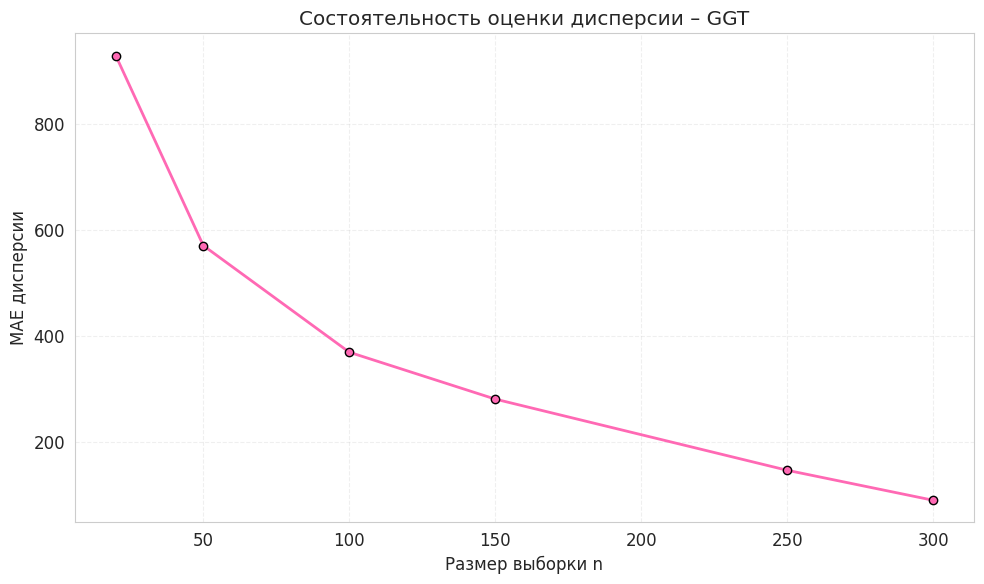

In [ ]:
# @title
plt.figure(figsize=(10, 6))
plt.plot(cons_g["n"], cons_g["MAE_variance"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE дисперсии")
plt.title("Состоятельность оценки дисперсии – GGT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

— Кривая также идёт вниз, — кивнул Старец, — Чем больше жителей мы берём в малое зеркало, тем точнее оно отражает истинную дисперсию всего Королевства.

<a id="rv03"></a>


## Случайная величина 03 — SGOT



> —  Пришло время последнего параметра `SGOT`, —  сказал Старец.
>
> Одна из девушек взяла в руки блокнот и на новой странице написала:





In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Третья случайная величина</h3>

    <div style="text-align: center; margin: 25px 0; font-size: 24px; font-family: 'Times New Roman', serif; color: #000;">
        X₃(ω) = sgot(ω)
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Что такое SGOT?</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            <b>sgot</b> — показатель аспартатаминотрансферазы (AST) в анализе крови. Это фермент, который содержится в клетках печени, сердца и мышц. При повреждении этих тканей AST попадает в кровь, и его уровень повышается.
        </p>
    </div>

    <div style="background-color: #fff0f5; padding: 18px; border-radius: 6px; border-left: 4px solid hotpink;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Природа величины</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            При случайном выборе человека заранее неизвестно значение SGOT. Величина отражает индивидуальное лабораторное измерение и не задаётся никакой формулой — её значение определяется биологическим состоянием конкретного пациента.
        </p>
    </div>
</div>
""")

### EDA & распределение


#### EDA

> — И снова описательная стаитистика, — сказал юноша.

In [ ]:
# @title
display(describe_rv(sgot).to_frame("sgot"))

,sgot
n,345.0000
mean,24.6435
median,23.0000
variance_unbiased,101.2940
std_unbiased,10.0645
min,5.0000
Q1,19.0000
Q3,27.0000
IQR,8.0000
max,82.0000


> — Давайте посмотрим в волшебное зеркало и посмотрим, как распределены значения среди жителей Королевства.

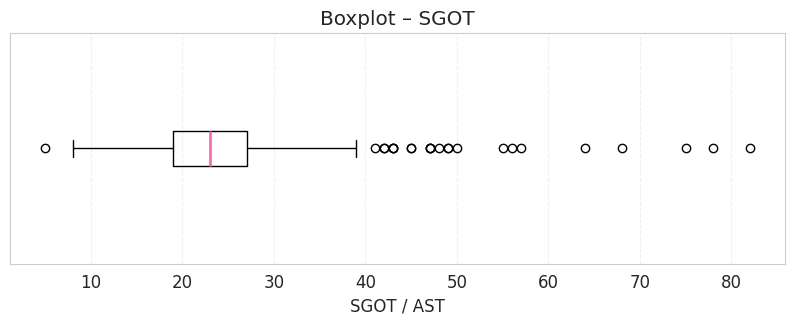

In [ ]:
# @title
plt.figure(figsize=(10, 3))
plt.boxplot(sgot, vert=False, medianprops={'color': 'hotpink', 'linewidth': 2})
plt.xlabel("SGOT / AST")
plt.title("Boxplot – SGOT")
plt.grid(alpha=0.3, linestyle='--')
plt.yticks([])
plt.show()

>  Исследователи посмотрели в магическое зеркало Boxplot. Значения колебались всего от 19 до 27.
>
> — И снова около 20 отдельно парщих точек, — сказал юноша, — давайте запишем результаты в блокнот.





In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 6px solid hotpink; padding: 25px; border-radius: 8px; margin: 20px 0; box-shadow: 0 4px 10px rgba(0,0,0,0.08); font-family: 'Segoe UI', sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 20px; display: flex; align-items: center;">
        Интерпретация описательной статистики
    </h3>

    <p style="font-size: 16px; color: #333; margin-bottom: 20px; line-height: 1.5;">
        В выборке из <b>345 пациентов</b> наблюдаются следующие характеристики распределения:
    </p>

    <ul style="font-size: 15px; line-height: 1.7; color: #444; list-style-type: none; padding-left: 5px;">
        <li style="margin-bottom: 12px;">
            <b>Среднее значение</b> составляет <b>24.64 Ед/л</b>, при этом <b>медиана</b> равна <b>23.00 Ед/л</b>.
            Превышение среднего над медианой указывает на <i>правостороннюю асимметрию</i> распределения.
        </li>
        <li style="margin-bottom: 12px;">
             <b>Межквартильный размах</b> показывает, что центральные 50% пациентов имеют уровень SGOT в диапазоне от <b>19 до 27 Ед/л</b>. Это свидетельствует о высокой концентрации большинства значений вокруг медианы.
        </li>
        <li style="margin-bottom: 12px;">
             <b>Разброс значений значителен:</b> от минимума в <b>5 Ед/л</b> до максимума в <b>82 Ед/л</b>.
        </li>
        <li style="margin-bottom: 12px;">
             <b>Коэффициент асимметрии ~ 2.29</b> подтверждает сильную правостороннюю асимметрию: большинство пациентов имеют умеренные значения, но присутствует небольшая группа с аномально высокими показателями («длинный хвост»).
        </li>
        <li style="margin-bottom: 12px;">
             <b>Эксцесс ~ 8.14</b> указывает на очень острый пик распределения (лептокуртоз) и тяжёлые хвосты по сравнению с нормальным законом.
        </li>
    </ul>

    <div style="margin-top: 25px; padding-top: 15px; border-top: 2px dashed #ffb3c6;">
        <b style="color: #d81b60; font-size: 17px;"> Вывод:</b>
        <span style="color: #333; font-size: 16px; font-weight: 500;">
            Распределение SGOT является <b>выраженно правосторонне асимметричным</b> и <b>не подчиняется нормальному закону</b>.
        </span>
    </div>
</div>
""")

#### Распределение

> — Природа у `gammagt` и `SGOT` одинаковая — это непрерывные случайные величины (биохимические показатели крови), поэтому для них справедливы одинаковые математические принципы и мы используем одни и те же формулы, — предположил юноша
>
> — Ты прав, — ответил Старец, — давайте запустим заклинание гистограммы

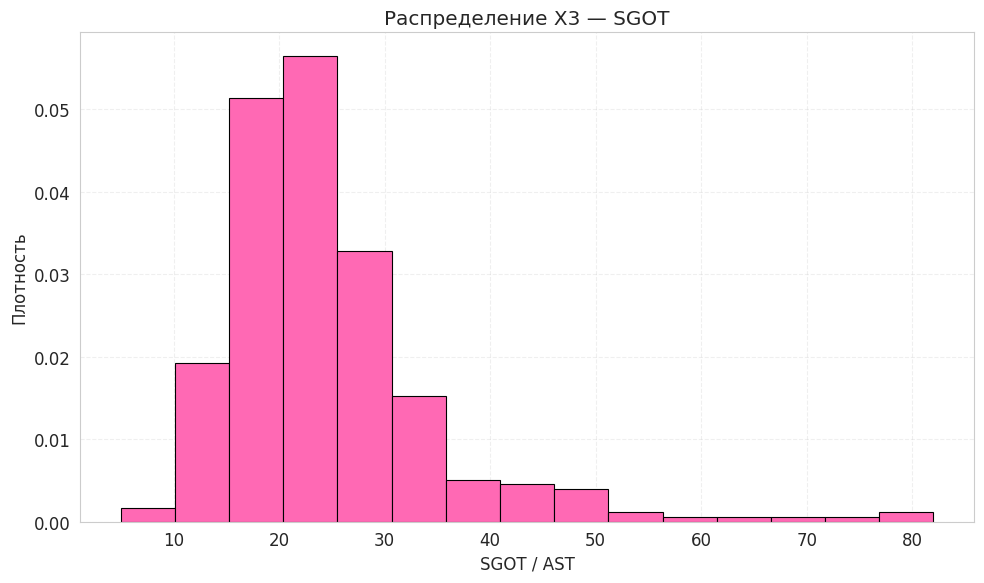

In [ ]:
# @title
plt.figure(figsize=(10, 6))
plt.hist(sgot, bins=15, density=True,
         color='hotpink', edgecolor='black', linewidth=0.8)
plt.xlabel("SGOT / AST")
plt.ylabel("Плотность")
plt.title("Распределение X3 — SGOT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Ну что ж, — сказала первая девушка, разглядывая зеркало, — пик почти 0.055 — выше, чем у `gammagt`. И хвост тянется только до 80, а не до 300.
>
> — Верно, — кивнул Старец. — SGOT — величина более сдержанная. У неё тоже правосторонняя асимметрия, но не такая драматичная.
>
> — Давайте снова используем ECDF. — предложил юноша.




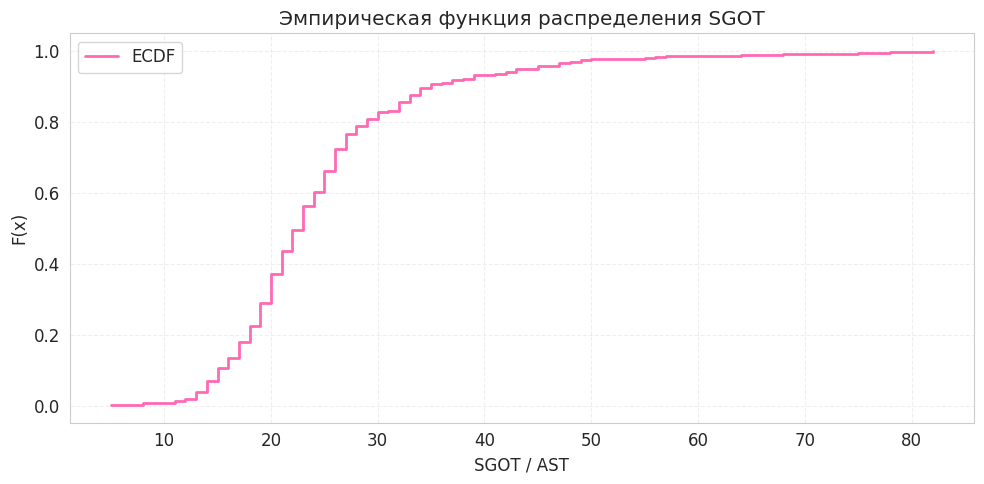

In [ ]:
# @title
x, y = ecdf_xy(sgot)

plt.figure(figsize=(10, 5))
plt.step(x, y, where="post", color='hotpink', linewidth=2, label='ECDF')
plt.xlabel("SGOT / AST")
plt.ylabel("F(x)")
plt.title("Эмпирическая функция распределения SGOT")
plt.grid(alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

> — Смотрите, — сказала первая девушка, указывая на зеркало, — кривая SGOT ведёт себя иначе, чем у `gammagt`. Помните, как у того взлёт был почти вертикальным в самом начале? А здесь подъём более плавный.
>
> Юноша прищурился, считывая отметки:
> — К 20 Ед/л функция достигает примерно 0.45. К 23 — пересекает 0.5, это медиана. К 30 — уже 0.75. А к 50 — почти 0.95.
>
> — Три величины — три характера, — подытожил Старец. — `drinks` дискретный и ступенчатый, `gammagt` резкий и длиннохвостый, `sgot` — более плавный, но всё равно скошенный. Ни один из них не хочет быть нормальным.
>
> — Что ж, — улыбнулась первая девушка, — тем интереснее будет проверить это формально.

### Гипотеза о нормальности

> — Давайте запишем гипотезы в блокнот и снова используем тест Шапиро-Уилка, — сказала одна из девушек

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;"> Формулировка гипотез для SGOT</h3>
    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;"> Нулевая и альтернативная гипотезы</h4>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-bottom: 15px;">
            <p style="font-size: 16px; color: #333; line-height: 1.8; margin: 0;">
                <b>H₀:</b> <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">sgot</code> имеет нормальное распределение.
            </p>
        </div>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
            <p style="font-size: 16px; color: #333; line-height: 1.8; margin: 0;">
                <b>H₁:</b> распределение <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">sgot</code> не является нормальным.
            </p>
        </div>
    </div>
</div>
""")

In [ ]:
shapiro_s = stats.shapiro(sgot)

print(f"Shapiro W = {shapiro_s.statistic:.6f}")
print(f"p-value = {shapiro_s.pvalue:.3e}")

Shapiro W = 0.814962
p-value = 1.403e-19


> — p-value равен 1.403e-19, — сказала первая девушка. —  Нулевая гипотеза снова отвергнута.
>
> — Давайте посмотрим на Q-Q plot,  —  сказал юноша.

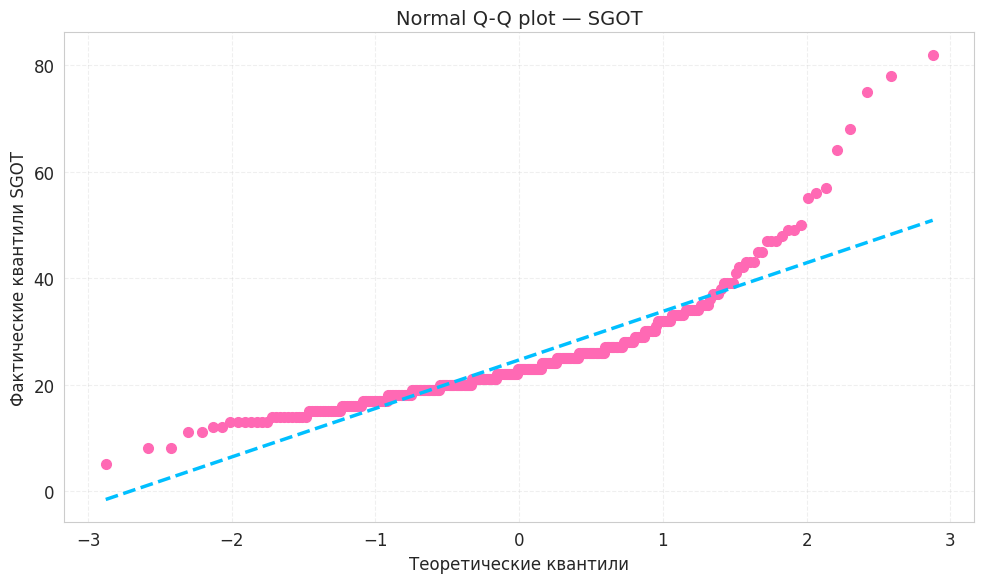

In [ ]:
# @title
fig, ax = plt.subplots(figsize=(10, 6))

stats.probplot(sgot, dist="norm", plot=ax)

lines = ax.get_lines()
lines[0].set_color('hotpink')
lines[0].set_marker('o')
lines[0].set_markersize(7)
lines[0].set_markeredgecolor('hotpink')
lines[0].set_markerfacecolor('hotpink')
lines[0].set_linestyle('None')

lines[1].set_color('deepskyblue')
lines[1].set_linewidth(2.5)
lines[1].set_linestyle('--')

ax.set_title("Normal Q-Q plot — SGOT", fontsize=14)
ax.set_xlabel("Теоретические квантили")
ax.set_ylabel("Фактические квантили SGOT")
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

>  —  В центре зеркала точки послушно ложаться на голубую тропу, но если взглянуть в правый верхний угол видно, как розовые следы жителей взмывают вверх.
>
> — Это срочно нужно записать в наш блокнот, доставай его скорее! — сказала одна из девочек.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 25px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 18px;"> Математическая интерпретация Q-Q plot</h3>

    <p style="font-size: 16px; color: #333; line-height: 1.6; margin-bottom: 20px;">
        На графике по оси X отложены теоретические квантили нормального распределения, а по оси Y — фактические квантили SGOT. Голубая пунктирная линия представляет собой эталонную прямую, на которой должны лежать точки, если данные подчиняются нормальному закону.
    </p>

    <div style="background-color: white; padding: 20px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Анализ отклонений:</h4>

        <ul style="font-size: 15px; color: #444; line-height: 1.7; list-style-type: none; padding-left: 0;">
            <li style="margin-bottom: 12px;">
                Точки образуют характерную дугу. В левой части графика они находятся выше прямой, а в правой — значительно ниже неё, прежде чем резко уйти вверх.
            </li>
            <li style="margin-bottom: 12px;">
                 Резкий отрыв точек вверх в правом хвосте свидетельствует о наличии экстремальных значений, которые тяжелее и дальше, чем допускает нормальное распределение.</b>
            </li>
            <li style="margin-bottom: 12px;">
                 Плотное скопление точек вокруг центра (квантиль 0) указывает на то, что большинство наблюдений сконцентрированы в узком диапазоне.
            </li>
        </ul>
    </div>

    <p style="font-size: 16px; color: #333; line-height: 1.6; margin-top: 0; border-top: 1px solid #ffd6e0; padding-top: 15px;">
        <b>Вывод:</b> распределение SGOT является существенно ненормальным, асимметричным и имеет тяжелые правые хвосты.
    </p>
</div>
""")

>  —  Давайте снова используем логорефмическое преобразование,  —  предложил Старец.


In [ ]:
# @title
log_sgot = np.log(sgot)

print("Skewness original:", round(stats.skew(sgot, bias=False), 4))
print("Skewness log:", round(stats.skew(log_sgot, bias=False), 4))

shapiro_log_s = stats.shapiro(log_sgot)
print(f"Shapiro log W = {shapiro_log_s.statistic:.6f}")
print(f"Shapiro log p-value = {shapiro_log_s.pvalue:.3e}")

Skewness original: 2.2931
Skewness log: 0.3366
Shapiro log W = 0.966283
Shapiro log p-value = 3.657e-07


> — Логарифмирование сново уменьшило ассиметрию, однако нормальность также не достиглась, —  сказал Старец.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 4px solid hotpink; padding: 12px 18px; border-radius: 6px; margin: 10px 0; box-shadow: 0 1px 3px rgba(0,0,0,0.04); font-family: sans-serif;">
    <p style="font-size: 15px; color: #333; line-height: 1.5; margin: 0;">
        Логарифмирование уменьшает асимметрию, однако точная нормальность также не достигается.
    </p>
</div>
""")

### Математическая модель распределения

> — Давайте снова сравним нормальное, логнормальное, экспоненциальное, гамма рспределения — предложила девушка.
>
> — Почему бы и нет. Судить снова будет критерий Акаике, — добавил Старец.



In [ ]:
fit_s, fitted_s = distribution_fit_table(sgot)
display(fit_s)

,distribution,AIC,KS_statistic_descriptive,MLE_params
1,Lognormal,2431.0272,0.0931,"(0.35232109686943325, 0, 23.07629660667206)"
2,Gamma,2458.1680,0.1182,"(7.772523294212377, 0, 3.170589180378493)"
3,Weibull,2550.8392,0.1567,"(2.463594468362426, 0, 27.71203415229293)"
0,Normal,2575.2856,0.1725,"(24.643478260869564, 10.049896938845267)"


> — Лучшим снова оказался Lognormal, а худшим Normal. Всё так же, как у `gammagt`, —  сказал юноша.
>
> — Это всё равно нужно зафиксировать, —  сказал Старец и взял перо...

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 18px 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">
    <p style="font-size: 16px; color: #333; line-height: 1.6; margin: 0;">
        Лучшей среди рассмотренных моделей оказалась Lognormal
        с параметрами μ ~ 3.14 и σ ~ 0.35 (AIC = 2431.03).
    </p>
</div>
""")

> — Давайте снова проверим, как это заклинание ложится на реальные данные. — предложил Старец.

,distribution,AIC,KS_statistic_descriptive,MLE_params
1,Lognormal,2431.0272,0.0931,"(0.35232109686943325, 0, 23.07629660667206)"
2,Gamma,2458.1680,0.1182,"(7.772523294212377, 0, 3.170589180378493)"
3,Weibull,2550.8392,0.1567,"(2.463594468362426, 0, 27.71203415229293)"
0,Normal,2575.2856,0.1725,"(24.643478260869564, 10.049896938845267)"


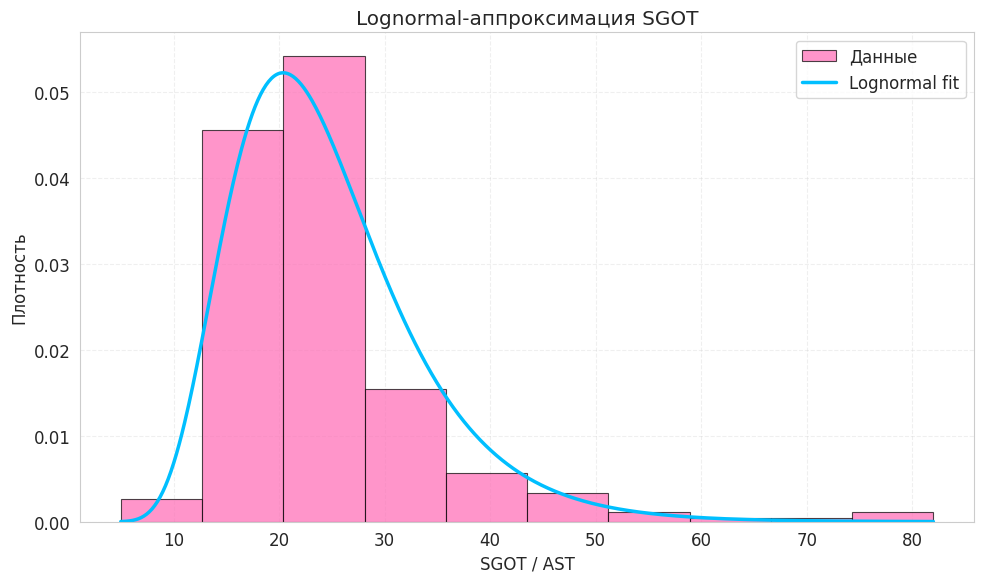

In [ ]:
# @title
table_s, fitted_s = distribution_fit_table(sgot)

display(table_s)

grid = np.linspace(sgot.min(), sgot.max(), 600)

plt.hist(sgot, bins="sturges", density=True,
         color='hotpink', edgecolor='black', linewidth=0.8, alpha=0.7, label="Данные")

dist_s, params_s = fitted_s["Lognormal"]
plt.plot(grid, dist_s.pdf(grid, *params_s),
         color='deepskyblue', linewidth=2.5, linestyle='-', label="Lognormal fit")

plt.xlabel("SGOT / AST")
plt.ylabel("Плотность")
plt.title("Lognormal-аппроксимация SGOT")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — В центральной части королевства заклинание сработало хорошо: пик кривой совпал с самым высоким столбцом. Но в дальних землях правого хвоста магия начала давать сбои. Одинокие столбцы на отметках 70 и 80 Ед/л остались почти неохваченными, — сказал Старец.
>
> — Заклинание Lognormal — хорошее приближение, — заключила первая исследовательница. — Но оно не способно удержать всех жителей, особенно тех, кто ушёл дальше всего от центра




### Нормализация / Стандартизация

> — Теперь научим `SGOT` разговаривать на всемирном языке, сказал юноша — будем использовать те же заклинания, что и раньше.

In [ ]:
# @title
s_z = z_standardize(sgot)
s_mm = minmax_normalize(sgot)

print("Z mean:", round(s_z.mean(), 10))
print("Z std:", round(s_z.std(ddof=1), 10))
print("Min-Max range:", s_mm.min(), s_mm.max())

Z mean: 0.0
Z std: 1.0
Min-Max range: 0.0 1.0


> — Теперь посмотрим, как заклинание изменило данные, — сказал юноша.

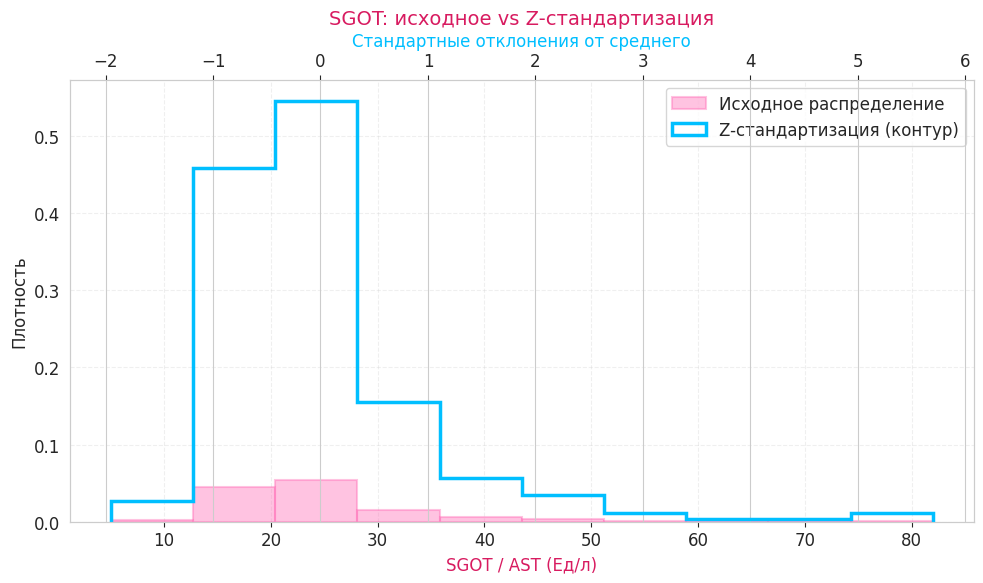

До: mean = 24.6435, std = 10.0645
После Z: mean = 0.0000000000, std = 1.0000000000


In [ ]:
# @title
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.hist(sgot, bins='sturges', density=True,
         color='hotpink', alpha=0.4, edgecolor='hotpink', linewidth=1.5,
         label='Исходное распределение')

ax2 = ax1.twiny()
ax2.hist(s_z, bins='sturges', density=True,
         histtype='step', color='deepskyblue', linewidth=2.5,
         label='Z-стандартизация (контур)')

ax1.set_xlabel('SGOT / AST (Ед/л)', fontsize=12, color='#d81b60')
ax2.set_xlabel('Стандартные отклонения от среднего', fontsize=12, color='deepskyblue')
ax1.set_ylabel('Плотность', fontsize=12)
ax1.set_title('SGOT: исходное vs Z-стандартизация', fontsize=14, color='#d81b60')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

ax1.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

print(f"До: mean = {sgot.mean():.4f}, std = {sgot.std(ddof=1):.4f}")
print(f"После Z: mean = {s_z.mean():.10f}, std = {s_z.std(ddof=1):.10f}")

> — Ура, всё работает, форма не изменена, — сказал юноша.

### Независимость и оценки

> — Давайте посчитаем mean, variance, median, Q1 и Q3 для всего Королевства и для выборки из 100 человек для `SGOT`. Мы уже делали так для `gammagt`.

In [ ]:
# @title
import pandas as pd

pop_mean = sgot.mean()
pop_median = sgot.median()
pop_var = sgot.var()
pop_q1 = sgot.quantile(0.25)
pop_q3 = sgot.quantile(0.75)

sw_mean = sample_without["sgot"].mean()
sw_median = sample_without["sgot"].median()
sw_var = sample_without["sgot"].var()
sw_q1 = sample_without["sgot"].quantile(0.25)
sw_q3 = sample_without["sgot"].quantile(0.75)

sr_mean = sample_with["sgot"].mean()
sr_median = sample_with["sgot"].median()
sr_var = sample_with["sgot"].var()
sr_q1 = sample_with["sgot"].quantile(0.25)
sr_q3 = sample_with["sgot"].quantile(0.75)

n_unique_with = len(np.unique(idx_with))
n_unique_without = len(np.unique(idx_without))

col_without = f"Без возвращения (n={n_unique_without})"
col_with = f"С возвращением (n=100, {n_unique_with} уникальных)"

comparison_s = pd.DataFrame({
    "Статистика": ["mean", "median", "variance", "Q1", "Q3"],
    "Популяция (N=345)": [round(pop_mean, 4), round(pop_median, 4), round(pop_var, 4), round(pop_q1, 4), round(pop_q3, 4)],
    col_without: [round(sw_mean, 4), round(sw_median, 4), round(sw_var, 4), round(sw_q1, 4), round(sw_q3, 4)],
    col_with: [round(sr_mean, 4), round(sr_median, 4), round(sr_var, 4), round(sr_q1, 4), round(sr_q3, 4)],
    "Ошибка без возвр.": [round(abs(sw_mean - pop_mean), 4),
                          round(abs(sw_median - pop_median), 4),
                          round(abs(sw_var - pop_var), 4),
                          round(abs(sw_q1 - pop_q1), 4),
                          round(abs(sw_q3 - pop_q3), 4)],
    "Ошибка с возвр.": [round(abs(sr_mean - pop_mean), 4),
                        round(abs(sr_median - pop_median), 4),
                        round(abs(sr_var - pop_var), 4),
                        round(abs(sr_q1 - pop_q1), 4),
                        round(abs(sr_q3 - pop_q3), 4)]
})

display(comparison_s)

,Статистика,Популяция (N=345),Без возвращения (n=100),"С возвращением (n=100, 89 уникальных)",Ошибка без возвр.,Ошибка с возвр.
0,mean,24.6435,25.5500,23.7700,0.9065,0.8735
1,median,23.0000,24.5000,22.0000,1.5000,1.0000
2,variance,101.2940,102.2702,71.2900,0.9762,30.0040
3,Q1,19.0000,19.0000,18.7500,0.0000,0.2500
4,Q3,27.0000,29.0000,27.0000,2.0000,0.0000


> — Q1 почти совпал в обеих выборках, — сказал юноша. — А вот медиана без возвращения отличается на 1.5, а с возвращением — всего на 1.0.
>
> — Cмотрите на дисперсию! — воскликнула первая девушка. — Без возвращения разница всего 0.98, а с возвращением — целых 30.
>
> Вторая исследовательница удивлённо подняла бровь:
> — То есть малое зеркало без возвращения почти идеально отразило разброс SGOT, несмотря на то, что это биохимический показатель.
>
> — Верно, — подтвердил Старец.
>
> — Давайте теперь возьмём выборки ещё меньше, как мы делали в прошлый раз, — сказал юноша.

In [ ]:
cons_s = consistency_experiment(sgot)
display(cons_s)

,n,MAE_mean,MAE_variance
0,20,1.7683,56.5099
1,50,1.0523,34.5272
2,100,0.6389,21.4437
3,150,0.4969,16.2555
4,250,0.2699,8.3495
5,300,0.1675,5.4425


> — Закономерность подтвердилась: чем больше группа, тем точнее она отражает всё Королевство. — сказала первая девушка.
>
> Исследовательница сразу записала эту закономерность в свой блокнот...


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 17px;">Интерпретация результатов эксперимента</h4>

    <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
        Результаты эксперимента подтверждают фундаментальную закономерность: с ростом объёма выборки точность оценок увеличивается. Зависимость средней абсолютной ошибки (MAE) от размера выборки <i>n</i> представлена в таблице:
    </p>

    <div style="background-color: #fff0f5; padding: 5px; border-radius: 6px; border: 1px solid #ffb3c6; margin-bottom: 20px;">
        <table style="width: 100%; border-collapse: collapse; font-size: 15px;">
            <tr style="background-color: #ffb3d9;">
                <th style="padding: 10px; border: 1px solid #d81b60; text-align: center; color: #000;">n</th>
                <th style="padding: 10px; border: 1px solid #d81b60; text-align: center; color: #000;">MAE<sub>mean</sub></th>
                <th style="padding: 10px; border: 1px solid #d81b60; text-align: center; color: #000;">MAE<sub>variance</sub></th>
                <th style="padding: 10px; border: 1px solid #d81b60; text-align: left; color: #000;">Интерпретация</th>
            </tr>
            <tr style="background-color: #ffe6f0;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;"><b>20</b></td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">1.7683</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">56.5099</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Высокая ошибка, малая выборка ненадёжна</td>
            </tr>
            <tr style="background-color: #fff0f5;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;"><b>100</b></td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">0.6389</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">21.4437</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Умеренная точность</td>
            </tr>
            <tr style="background-color: #ffe6f0;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;"><b>300</b></td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">0.1675</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">5.4425</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Высокая точность оценок</td>
            </tr>
        </table>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Математическое обоснование</h4>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin-bottom: 15px;">
            Наблюдаемая закономерность является следствием Закона больших чисел:
        </p>

        <div style="text-align: center; margin: 20px 0; font-size: 18px; font-family: 'Times New Roman', serif; color: #000;">
            lim<sub>n→∞</sub> P(|X̄ₙ − μ| &lt; ε) = 1
        </div>

        <p style="font-size: 14px; color: #555; line-height: 1.6; margin-bottom: 15px;">
            где X̄ₙ — выборочное среднее, μ — математическое ожидание генеральной совокупности, ε — произвольно малое число.
        </p>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            При увеличении <i>n</i> дисперсия выборочного среднего уменьшается по закону:
        </p>

        <div style="text-align: center; margin: 15px 0; font-size: 18px; font-family: 'Times New Roman', serif; color: #000;">
            D(X̄ₙ) = σ²/n
        </div>
    </div>
</div>
""")

n,MAEmean,MAEvariance,Интерпретация
20,1.7683,56.5099,"Высокая ошибка, малая выборка ненадёжна"
100,0.6389,21.4437,Умеренная точность
300,0.1675,5.4425,Высокая точность оценок


> — Теперь перенесём числа на график, всё как для `gammagt`, — сказал юноша.

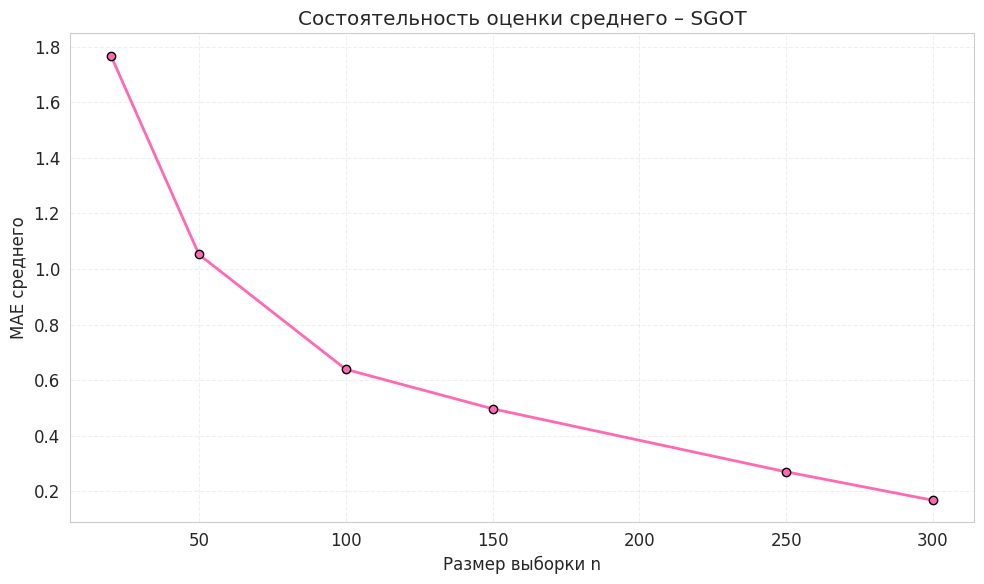

In [ ]:
# @title
cons_s = consistency_experiment(sgot)

plt.plot(cons_s["n"], cons_s["MAE_mean"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE среднего")
plt.title("Состоятельность оценки среднего – SGOT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

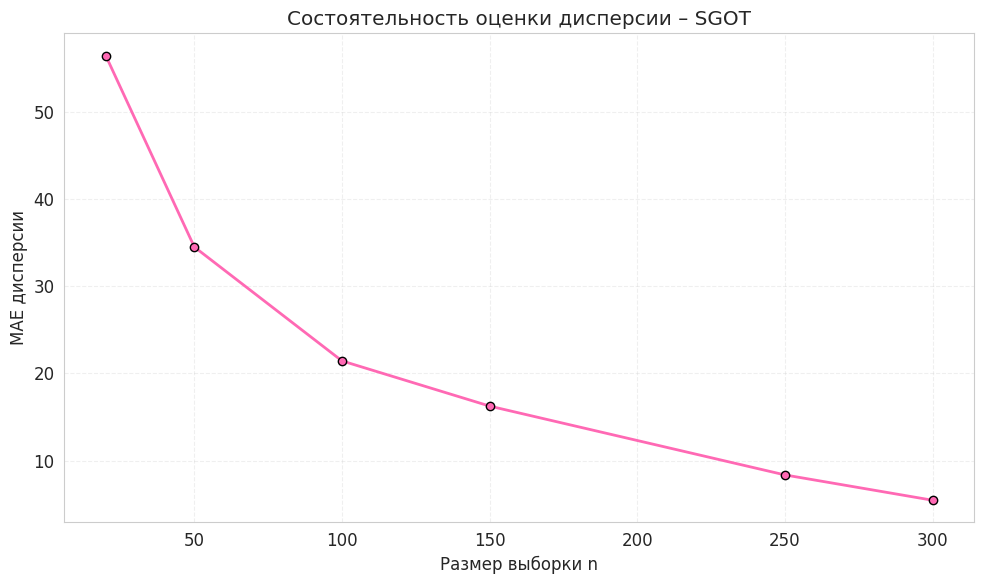

In [ ]:
# @title
plt.plot(cons_s["n"], cons_s["MAE_variance"],
         color='hotpink', marker='o', linewidth=2, markersize=6, markeredgecolor='black')
plt.xlabel("Размер выборки n")
plt.ylabel("MAE дисперсии")
plt.title("Состоятельность оценки дисперсии – SGOT")
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — График чётко подтвердил ожидаемое: кривая плавно идёт вниз, — сказал Старец.

<a id="hypothesis-testing"></a>
## Связь велчин

> — Мы изучили каждую величину по отдельности. Но интереснее смотреть на пары величин. — сказала первая девушка,  
>
> Вторая исследовательница открыла новую страницу блокнота:
> — Нам нужно проверить три пары: `drinks` и `gammagt`, `drinks` и `sgot`, и `gammagt` и `sgot`. Для каждой посчитать коэффициент связи и построить диаграмму рассеяния.
>
> — И если связь окажется сильной, — добавил Старец, — значит, величины зависимы.   
>
> — А какие заклинания используем? — спросил юноша.
>
> — Два, — ответила первая девушка. — Пирсон для линейной связи и Спирмен для любой монотонной.
>
> Исследователи склонились над зеркалом, там появлялось много квадратиков — это же тепловая карта... — воскликнул юноша.

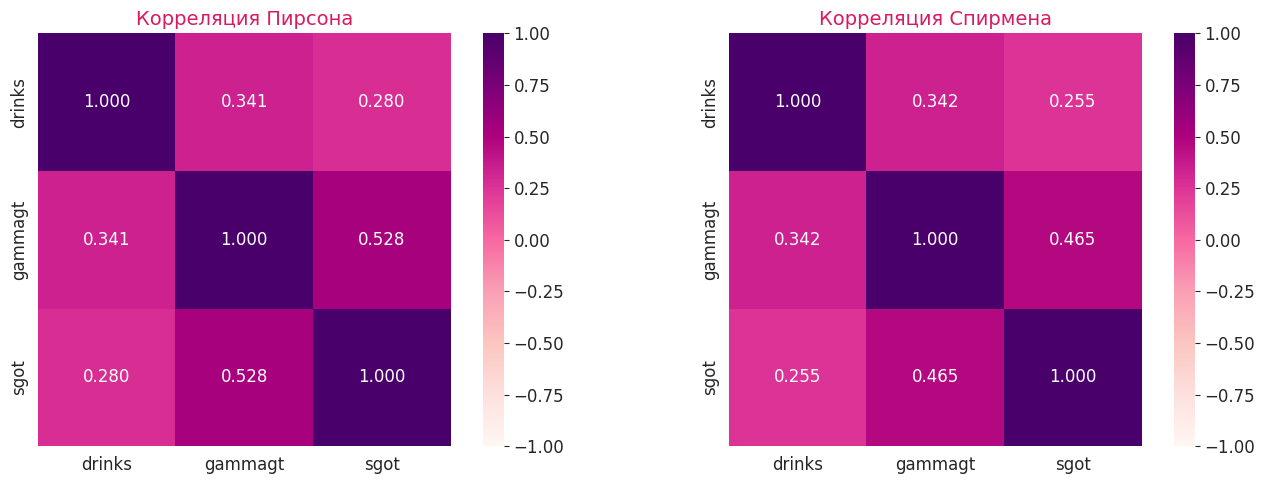

In [ ]:
# @title
import seaborn as sns

corr_pearson = df[['drinks', 'gammagt', 'sgot']].corr(method='pearson')
corr_spearman = df[['drinks', 'gammagt', 'sgot']].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_pearson, annot=True, cmap='RdPu', fmt='.3f',
            vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title('Корреляция Пирсона', fontsize=14, color='#d81b60')

sns.heatmap(corr_spearman, annot=True, cmap='RdPu', fmt='.3f',
            vmin=-1, vmax=1, ax=axes[1], square=True)
axes[1].set_title('Корреляция Спирмена', fontsize=14, color='#d81b60')

plt.tight_layout()
plt.show()

> — Самая тёмная ячейка — на пересечениях `gammagt` и `sgot`, — сказала одна из девушек.
>
> Юноша прищурился:
> — А ячейки с `drinks` сильно светлее.
> — Давайте посмотрим на диаграммы рассеяния, — предложила вторая девушка. — Так нам будет видно, как именно выстраиваются точки.

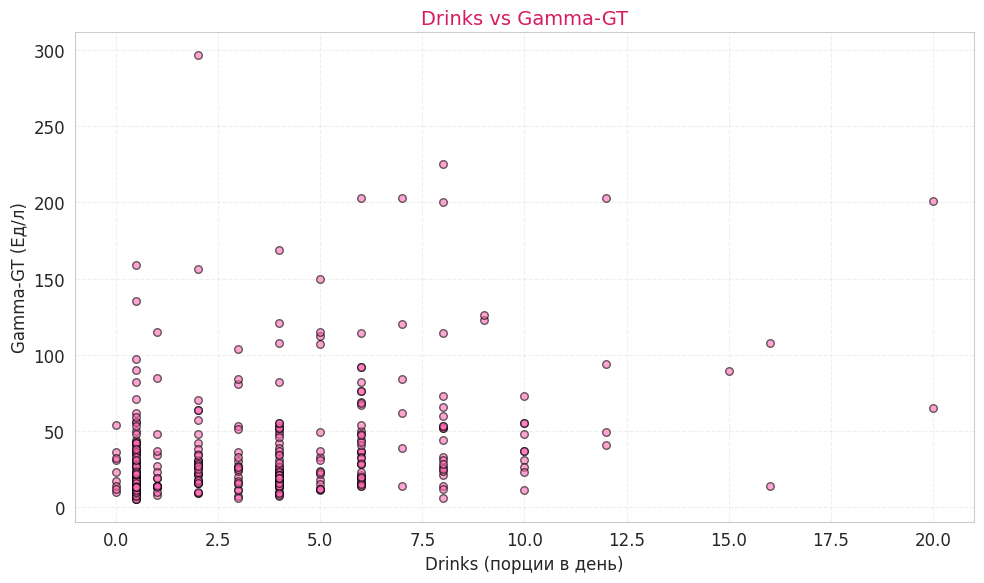

In [ ]:
# @title

plt.figure(figsize=(10, 6))
plt.scatter(df['drinks'], df['gammagt'], color='hotpink', alpha=0.6, edgecolors='black', s=30)
plt.title('Drinks vs Gamma-GT', fontsize=14, color='#d81b60')
plt.xlabel('Drinks (порции в день)', fontsize=12)
plt.ylabel('Gamma-GT (Ед/л)', fontsize=12)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Точки размазаны по всему полю. При нуле порций GGT бывает как 10, так и 50. При 10 порциях - тоже разброс огромный, связь очень слабая. Корреляция всего 0.34 — сказал юноша.
>
> — Но некоторая зависимость всё же есть, — заметила вторая девушка — В среднем, чем больше пьёшь, тем выше Gamma-GT. Просто связь прослеживается не так хорошо, как, возможно, хотелось бы.
>
> — Посмотрим на вторую пару — сказал Старец.

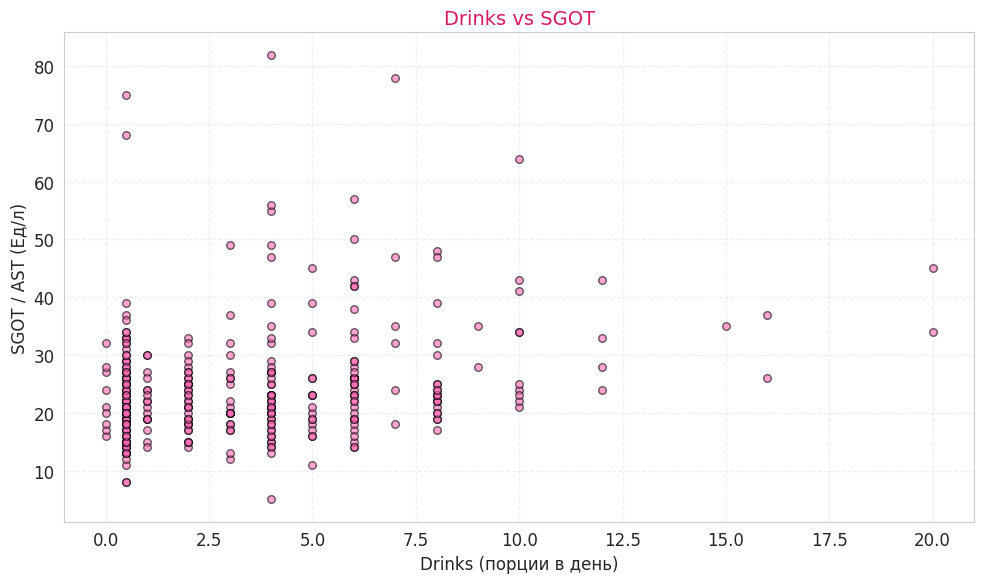

In [ ]:
# @title

plt.figure(figsize=(10, 6))
plt.scatter(df['drinks'], df['sgot'], color='hotpink', alpha=0.6, edgecolors='black', s=30)
plt.title('Drinks vs SGOT', fontsize=14, color='#d81b60')
plt.xlabel('Drinks (порции в день)', fontsize=12)
plt.ylabel('SGOT / AST (Ед/л)', fontsize=12)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Ещё более размыто, — сказала первая девушка. — Корреляция всего 0.25-0.28. Почти горизонтальное облако. То есть алкоголь ещё слабее связан с SGOT, чем с GGT?
>
> — Выходит что так — подтвердил Старец. — SGOT - это фермент не только печени, но и сердца с мышцами. Поэтому на него влияет не только алкоголь, но и физическая нагрузка, травмы и другие факторы. А значит связь размывается.
>
> — Теперь самое интересное, — улыбнулась вторая девушка. — Два фермента печени. Давайте посмотрим, как они связаны друг с другом.


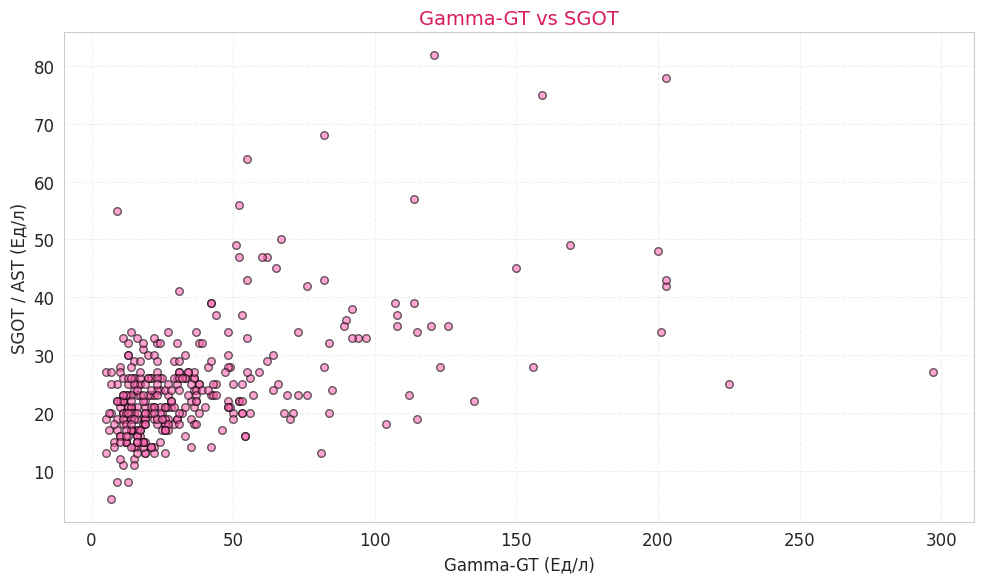

In [ ]:
# @title
plt.figure(figsize=(10, 6))
plt.scatter(df['gammagt'], df['sgot'], color='hotpink', alpha=0.6, edgecolors='black', s=30)
plt.title('Gamma-GT vs SGOT', fontsize=14, color='#d81b60')
plt.xlabel('Gamma-GT (Ед/л)', fontsize=12)
plt.ylabel('SGOT / AST (Ед/л)', fontsize=12)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

> — Смотрите, точки выстраиваются в розовое облако, тянущееся вверх-вправо! — воскликнула первая девушка.
>
> Юноша прищурился:

> — И правда, при низком GGT (до 50) SGOT тоже низкий (до 40). А при высоких значениях Gamma-GT (100-200) SGOT тоже растёт.
>
> — Это умеренная связь, — кивнул Старец. — Корреляция 0.47 - 0.53 - самая сильная из трёх пар.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 17px;">Наиболее выраженная связь: Gamma-GT ↔ SGOT</h4>

    <div style="background-color: #fff0f5; padding: 5px; border-radius: 6px; border: 1px solid #ffb3c6; margin-bottom: 15px;">
        <table style="width: 100%; border-collapse: collapse; font-size: 15px;">
            <tr style="background-color: #ffb3d9;">
                <th style="padding: 10px; border: 1px solid #d81b60; text-align: left; color: #000;">Коэффициент</th>
                <th style="padding: 10px; border: 1px solid #d81b60; text-align: center; color: #000;">Значение</th>
                <th style="padding: 10px; border: 1px solid #d81b60; text-align: left; color: #000;">Интерпретация</th>
            </tr>
            <tr style="background-color: #ffe6f0;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Pearson (r)</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">~ 0.528</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Умеренная линейная связь</td>
            </tr>
            <tr style="background-color: #fff0f5;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Spearman (ρₛ)</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">~ 0.465</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Умеренная монотонная связь</td>
            </tr>
            <tr style="background-color: #ffe6f0;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">p-value</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">&lt; 0.001</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Статистически значимо</td>
            </tr>
        </table>
    </div>

    <div style="padding: 15px 18px; border-radius: 6px;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
          <b>Вывод:</b> Полученные значения свидетельствуют об умеренной связи между Gamma-GT и SGOT. Это согласуется с биологическим смыслом: оба показателя являются маркерами повреждения клеток печени и указывают на одни и те же патологические процессы.
        </p>
    </div>
</div>
""")

Коэффициент,Значение,Интерпретация
Pearson (r),~ 0.528,Умеренная линейная связь
Spearman (ρₛ),~ 0.465,Умеренная монотонная связь
p-value,< 0.001,Статистически значимо


## Проверка гипотезы

> — Мы уже знаем, что нити корреляции тянутся от `drinks` к `gammagt`, — сказала первая девушка, перелистывая страницы блокнота. — Чем больше пьёшь, тем выше уровень фермента. Но это лишь общая картина.
>
> Юноша нахмурился:
> — А если посмотреть точнее? Не на всех сразу, а по группам?
>
> — Отличная мысль, — кивнул Старец. — Разделите жителей Королевства на две группы.


In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Формулировка гипотез</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Допустим две гипотезы:</h4>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-bottom: 15px;">
            <p style="font-size: 16px; color: #333; line-height: 1.8; margin: 0;">
                <b>H₀:</b> распределение <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">Gamma-GT</code> одинаково для всех.
            </p>
        </div>

        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
            <p style="font-size: 16px; color: #333; line-height: 1.8; margin: 0;">
                <b>H₁:</b> распределение <code style="font-family: 'Courier New', monospace; background-color: #ffe6f0; padding: 2px 6px; border-radius: 3px;">Gamma-GT</code> различается в зависимости от того, сколько пьёт человек (drinks > 5 или <= 5).
            </p>
        </div>
    </div>
</div>
""")

> — Теперь нужно выбрать критерий, — сказал Старец.
>
> — А я уже кое-что написал на этот счёт, смотрите — сказал юноша.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Критерий Манна–Уитни?</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Причины выбрать его:</h4>

        <ul style="font-size: 15px; color: #333; line-height: 1.8; list-style-type: none; padding-left: 0; margin: 0;">
            <li style="margin-bottom: 12px;">
                Причина 1. Данные ненормальны. Мы уже доказали это тестом Шапиро–Уилка: p-value = 6.481 × 10⁻²⁵.  t-критерий Стьюдента требует нормальности — он просто не сработает честно.
            </li>
            <li style="margin-bottom: 12px;">
               Причина 2. Две независимые выборки. У нас две разные группы жителей — умеренно пьющие и много пьющие. Они не связаны между собой. Нужен критерий именно для независимых групп.
            </li>
            <li style="margin-bottom: 12px;">
               Причина 3. Тяжёлые хвосты и выбросы. Gamma-GT имеет выбросы до 300 Ед/л. Критерий, работающий с рангами, устойчив к ним — он работает не с абсолютнми значениями, а с порядком.
            </li>
        </ul>
    </div>
</div>
""")

> — Отлично! Тогда остановимся на этом критерии, — сказал Старец.
>
> Одна из исследовательниц уже тянулась к заклинанию группировки:

> — Посчитаем для каждой группы размер, среднее, медиану, первый и третий квартили по GGT. Посмотрим, насколько они различаются.

In [ ]:
# @title
low_drinks = df.loc[df["drinks"] <= 5, "gammagt"]
high_drinks = df.loc[df["drinks"] > 5, "gammagt"]

group_table = pd.DataFrame({
    "drinks <= 5": [
        len(low_drinks), low_drinks.mean(), low_drinks.median(),
        low_drinks.quantile(0.25), low_drinks.quantile(0.75),
    ],
    "drinks > 5": [
        len(high_drinks), high_drinks.mean(), high_drinks.median(),
        high_drinks.quantile(0.25), high_drinks.quantile(0.75),
    ],
}, index=["n", "mean_GGT", "median_GGT", "Q1_GGT", "Q3_GGT"])

display(group_table)

,drinks <= 5,drinks > 5
n,257.0000,88.0000
mean_GGT,31.8171,57.1705
median_GGT,22.0000,42.0000
Q1_GGT,14.0000,23.0000
Q3_GGT,36.0000,70.0000


> — Ухты пухты! — воскликнула первая девушка, — Смотрите на средние! У умеренно пьющих GGT в среднем 31.8 Ед/л, а у много пьющих - 57.2. Почти в два раза выше!
>
> Юноша пробежал взглядом по строкам:

> — И размеры групп разные: 257 человек в первой и всего 88 во второй. То есть большинство жителей Королевства пьют умеренно.
>
> — Но — строго поднял палец Старец, — мы видим лишь описательную картину. Чтобы сказать, что разница значима, а не случайна, нужен формальный тест - тест Манна-Уитни.

In [ ]:
# @title
mw = stats.mannwhitneyu(low_drinks, high_drinks, alternative="two-sided")

n1, n2 = len(low_drinks), len(high_drinks)
rank_biserial = 1 - (2 * mw.statistic) / (n1 * n2)

print(f"Манн-Уитни U = {mw.statistic:.1f}")
print(f"p-value = {mw.pvalue:.3e}")
print(f"rank-biserial correlation = {rank_biserial:.4f}")

Манн-Уитни U = 6539.0
p-value = 3.487e-09
rank-biserial correlation = 0.4217


Исследователи записали результат теста Манна-Уитни в свой блокнот:

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 17px;">Интерпретация результатов теста Манна–Уитни</h4>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Результаты теста</h4>

        <table style="width: 100%; border-collapse: collapse; font-size: 15px;">
            <tr style="background-color: #ffe6f0;">
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: left; color: #000;">Показатель</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">Значение</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: left; color: #000;">Смысл</th>
            </tr>
            <tr>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">U-статистика</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">6539.0</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Мера разделения рангов между группами</td>
            </tr>
            <tr style="background-color: #fff9e6;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">p-value</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">3.49 × 10⁻⁹</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Вероятность случайного получения такого результата</td>
            </tr>
            <tr>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Rank-biserial correlation</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">0.4217</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Мера силы эффекта (от −1 до +1)</td>
            </tr>
        </table>
    </div>
    <div style="background-color: #fff0f5; padding: 18px; border-radius: 6px; border-left: 4px solid hotpink;">
        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            <b>Вывод:</b> Тест Манна–Уитни показал статистически значимое различие (p &lt; 0.001) в распределении Gamma-GT между группами с низним и высоким потреблением алкоголя. Размер эффекта (r<sub>rb</sub> ~ 0.42) является умеренным: пациенты, употребляющие более 5 порций алкоголя в день, имеют систематически более высокий уровень Gamma-GT, чем те, кто пьёт меньше. Это подтверждает биологическую связь между потреблением алкоголя и повреждением печени.
        </p>
    </div>
</div>
""")

Показатель,Значение,Смысл
U-статистика,6539.0,Мера разделения рангов между группами
p-value,3.49 × 10⁻⁹,Вероятность случайного получения такого результата
Rank-biserial correlation,0.4217,Мера силы эффекта (от −1 до +1)


> — Теперь отобразим наши результаты в волшебном зеркале — сказал Старец.

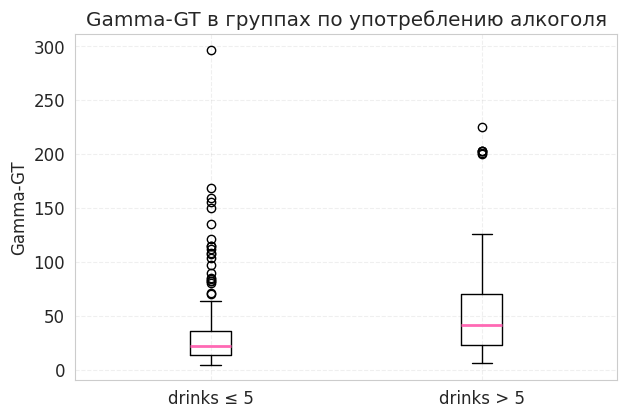

In [ ]:
# @title
plt.figure(figsize=(7, 4.5))
plt.boxplot(
    [low_drinks, high_drinks],
    tick_labels=["drinks ≤ 5", "drinks > 5"],
    medianprops={'color': 'hotpink', 'linewidth': 2}
)
plt.ylabel("Gamma-GT")
plt.title("Gamma-GT в группах по употреблению алкоголя")
plt.grid(alpha=0.3, linestyle='--')
plt.show()

> Исследователи записали выводы по гипотезе в совй блокнот.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Вывод по гипотезе</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Сравнение медиан</h4>

        <table style="width: 100%; border-collapse: collapse; font-size: 15px;">
            <tr style="background-color: #ffe6f0;">
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: left; color: #000;">Группа</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">n</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">Медиана GGT (Ед/л)</th>
            </tr>
            <tr>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">drinks ≤ 5 (умеренное)</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">257</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">~ 22</td>
            </tr>
            <tr style="background-color: #fff9e6;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">drinks > 5 (высокое)</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">88</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">~ 42</td>
            </tr>
        </table>

        <p style="font-size: 14px; color: #555; line-height: 1.5; margin: 15px 0 0 0; font-style: italic;">
            Медиана GGT в группе с высоким потреблением алкоголя почти в 2 раза выше, чем в группе с умеренным.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Результат теста Манна–Уитни</h4>

        <div style="text-align: center; margin: 15px 0; font-size: 20px; font-family: 'Times New Roman', serif; color: #000;">
            p-value ~ 3.49 × 10⁻⁹
        </div>

        <div style="background-color: #fff0f5; padding: 12px 15px; border-radius: 6px; border-left: 4px solid hotpink; margin-top: 15px;">
            <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
                Решение: при уровне значимости α = 0.05 выполняется условие
            </p>
            <div style="text-align: center; margin: 10px 0; font-size: 17px; font-family: 'Times New Roman', serif; color: #000;">
                p-value << α
            </div>
            <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
                Следовательно, нулевая гипотеза H₀ отвергается. Распределения GGT в двух группах статистически значимо различаются.
            </p>
        </div>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Размер эффекта</h4>

        <div style="text-align: center; margin: 15px 0; font-size: 20px; font-family: 'Times New Roman', serif; color: #000;">
            r<sub>rb</sub> ~ 0.42
        </div>

        <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
            Rank-biserial correlation ~ 0.42 указывает на умеренный эффект: пациенты с высоким потреблением алкоголя имеют систематически более высокие значения GGT, чем пациенты с умеренным потреблением.
        </p>
    </div>
</div>
""")

Группа,n,Медиана GGT (Ед/л)
drinks ≤ 5 (умеренное),257,~ 22
drinks > 5 (высокое),88,~ 42


## Сравнение с нормой

— Ребятки, — сказал Старец — вы же не забыли, зачем мы все тут собрались?

— Ой, чего-то немного запамятовали, пока производили все эти вычисления — ответили исследователи.

— Тогда я вам напомню. — сказа Старец, поглаживая бороду — мы собрались здесь чтобы проверить, действительно ли в нашей любимой лавке торгуют некачетсвенным алкоголем. Для этого нам нужно сравнить полученные нами анализы с нормативными документами, которые хранятся в главной лаборатории нашего королевства, я как раз взял парочку копий перед нашим путешествием.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Референсные значения ферментов печени (мужчины)</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">

        <table style="width: 100%; border-collapse: collapse; font-size: 15px; margin-bottom: 15px;">
            <tr style="background-color: #ffe6f0;">
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: left; color: #000;">Показатель</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">Референсный интервал (норма)</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: left; color: #000;">Клиническое значение</th>
            </tr>
            <tr>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">SGOT (АСТ)<br><span style="font-size:12px; color:#666;">Аспартатаминотрансфераза</span></td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">10 - 40 Ед/л</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Маркер повреждения клеток печени и миокарда. Менее специфичен для алкоголя.</td>
            </tr>
            <tr style="background-color: #fff9e6;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">GGT<br><span style="font-size:12px; color:#666;">Гамма-глутамилтранспептидаза</span></td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">9 - 48 Ед/л</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">Высокочувствительный и специфичный маркер холестаза и алкогольной интоксикации печени.</td>
            </tr>
        </table>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Источники нормативных данных</h4>
        <ol style="font-size: 14px; color: #333; line-height: 1.8; padding-left: 20px; margin: 0;">
            <li style="margin-bottom: 8px;">
                Клинические рекомендации «Алкогольная болезнь печени» (Ассоциация врачей-гепатологов и гастроэнтерологов, РФ). Утверждают GGT как ключевой маркер алкогольного поражения, где значения > 50 Ед/л рассматриваются как достоверный признак патологии.
            </li>
            <li style="margin-bottom: 8px;">
                Стандарты лабораторной диагностики (Приказ Минздрава РФ, международные протоколы IFCC). Референсные интервалы для ферментов печени у взрослых мужчин.
            </li>
        </ol>
    </div>

</div>
""")

Показатель,Референсный интервал (норма),Клиническое значение
SGOT (АСТ)Аспартатаминотрансфераза,10 - 40 Ед/л,Маркер повреждения клеток печени и миокарда. Менее специфичен для алкоголя.
GGTГамма-глутамилтранспептидаза,9 - 48 Ед/л,Высокочувствительный и специфичный маркер холестаза и алкогольной интоксикации печени.


— Так, теперь давайте сравним это с тем, что мы имеем в нашем мини исследовании — сказал юноша

— Только давайте сначала разделим наших мужчин на две выборки, как уже делали раньше — сказал одна из девушек, перед тем как начала читать заклинание

In [ ]:
# @title
# Референсные значения для мужчин
sgot_norm_upper = 40  # Ед/л
ggt_norm_upper = 48   # Ед/л

# Группы
low_drinks = df[df['drinks'] <= 5]
high_drinks = df[df['drinks'] > 5]

print("СРАВНЕНИЕ С РЕФЕРЕНСНЫМИ ЗНАЧЕНИЯМИ")

print(f"\nSGOT (норма: до {sgot_norm_upper} Ед/л):")
print(f"  Вся выборка: медиана = {df['sgot'].median():.1f}, среднее = {df['sgot'].mean():.1f}")
print(f"  Выше нормы: {(df['sgot'] > sgot_norm_upper).sum()} из {len(df)} ({(df['sgot'] > sgot_norm_upper).mean()*100:.1f}%)")
print(f"\n  Умеренно пьющие (drinks <= 5):")
print(f"    Медиана = {low_drinks['sgot'].median():.1f}, среднее = {low_drinks['sgot'].mean():.1f}")
print(f"    Выше нормы: {(low_drinks['sgot'] > sgot_norm_upper).sum()} из {len(low_drinks)} ({(low_drinks['sgot'] > sgot_norm_upper).mean()*100:.1f}%)")
print(f"\n  Много пьющие (drinks > 5):")
print(f"    Медиана = {high_drinks['sgot'].median():.1f}, среднее = {high_drinks['sgot'].mean():.1f}")
print(f"    Выше нормы: {(high_drinks['sgot'] > sgot_norm_upper).sum()} из {len(high_drinks)} ({(high_drinks['sgot'] > sgot_norm_upper).mean()*100:.1f}%)")

print(f"\nGGT (норма: до {ggt_norm_upper} Ед/л):")
print(f"  Вся выборка: медиана = {df['gammagt'].median():.1f}, среднее = {df['gammagt'].mean():.1f}")
print(f"  Выше нормы: {(df['gammagt'] > ggt_norm_upper).sum()} из {len(df)} ({(df['gammagt'] > ggt_norm_upper).mean()*100:.1f}%)")
print(f"\n  Умеренно пьющие (drinks <= 5):")
print(f"    Медиана = {low_drinks['gammagt'].median():.1f}, среднее = {low_drinks['gammagt'].mean():.1f}")
print(f"    Выше нормы: {(low_drinks['gammagt'] > ggt_norm_upper).sum()} из {len(low_drinks)} ({(low_drinks['gammagt'] > ggt_norm_upper).mean()*100:.1f}%)")
print(f"\n  Много пьющие (drinks > 5):")
print(f"    Медиана = {high_drinks['gammagt'].median():.1f}, среднее = {high_drinks['gammagt'].mean():.1f}")
print(f"    Выше нормы: {(high_drinks['gammagt'] > ggt_norm_upper).sum()} из {len(high_drinks)} ({(high_drinks['gammagt'] > ggt_norm_upper).mean()*100:.1f}%)")

СРАВНЕНИЕ С РЕФЕРЕНСНЫМИ ЗНАЧЕНИЯМИ

SGOT (норма: до 40 Ед/л):
  Вся выборка: медиана = 23.0, среднее = 24.6
  Выше нормы: 23 из 345 (6.7%)

  Умеренно пьющие (drinks <= 5):
    Медиана = 21.0, среднее = 23.2
    Выше нормы: 9 из 257 (3.5%)

  Много пьющие (drinks > 5):
    Медиана = 25.5, среднее = 28.9
    Выше нормы: 14 из 88 (15.9%)

GGT (норма: до 48 Ед/л):
  Вся выборка: медиана = 25.0, среднее = 38.3
  Выше нормы: 79 из 345 (22.9%)

  Умеренно пьющие (drinks <= 5):
    Медиана = 22.0, среднее = 31.8
    Выше нормы: 41 из 257 (16.0%)

  Много пьющие (drinks > 5):
    Медиана = 42.0, среднее = 57.2
    Выше нормы: 38 из 88 (43.2%)


— Ребят, это всё, конечно, хорошо, но я так ничего и не поняла. Давайте это визуализируем! — сказала вторая девушка и прочитала заклинание

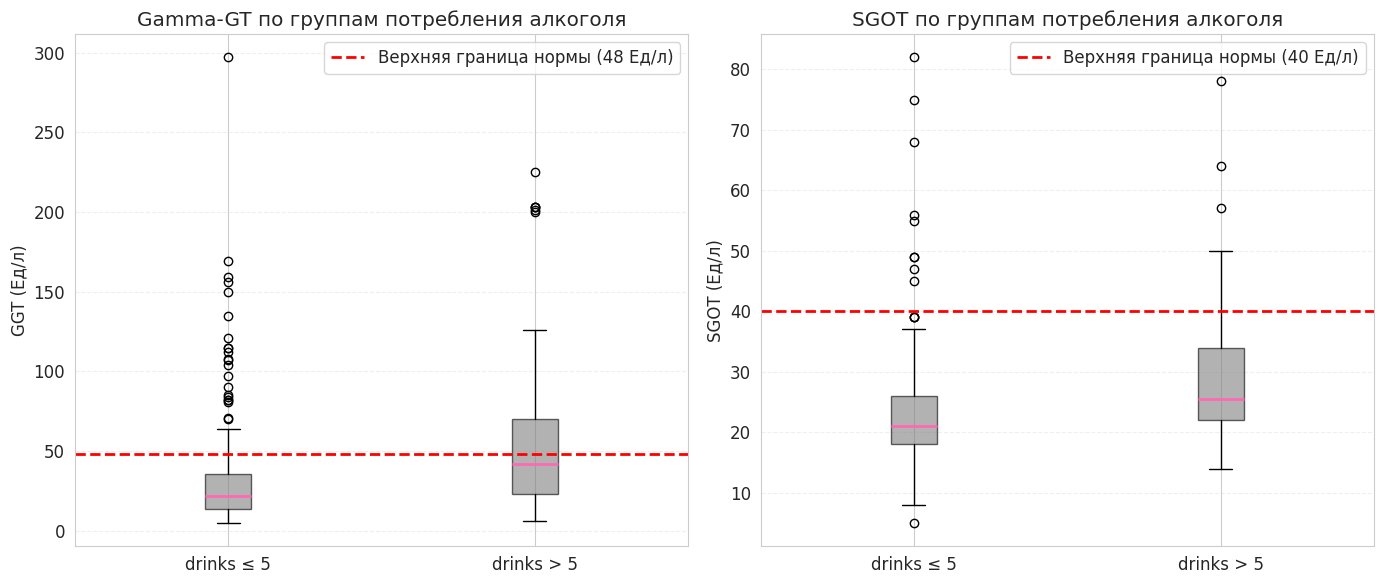

In [ ]:
# @title
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# GGT
data_ggt = [low_drinks['gammagt'], high_drinks['gammagt']]
bp1 = axes[0].boxplot(data_ggt, tick_labels=['drinks ≤ 5', 'drinks > 5'], patch_artist=True,
                       medianprops={'color': 'hotpink', 'linewidth': 2})
for patch in bp1['boxes']:
    patch.set_facecolor('#808080')
    patch.set_alpha(0.6)
axes[0].axhline(y=ggt_norm_upper, color='red', linestyle='--', linewidth=2, label=f'Верхняя граница нормы ({ggt_norm_upper} Ед/л)')
axes[0].set_ylabel('GGT (Ед/л)')
axes[0].set_title('Gamma-GT по группам потребления алкоголя')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3, linestyle='--')

# SGOT
data_sgot = [low_drinks['sgot'], high_drinks['sgot']]
bp2 = axes[1].boxplot(data_sgot, tick_labels=['drinks ≤ 5', 'drinks > 5'], patch_artist=True,
                       medianprops={'color': 'hotpink', 'linewidth': 2})
for patch in bp2['boxes']:
    patch.set_facecolor('#808080')
    patch.set_alpha(0.6)
axes[1].axhline(y=sgot_norm_upper, color='red', linestyle='--', linewidth=2, label=f'Верхняя граница нормы ({sgot_norm_upper} Ед/л)')
axes[1].set_ylabel('SGOT (Ед/л)')
axes[1].set_title('SGOT по группам потребления алкоголя')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

— Хммм... — протянул Старец — В большинстве случаев умеренное потребление не выводит пределы за рамки нормы. Но с повышением уровня употребления картина меняется.

— Да, особенно хорошо это видно по GGT — согласился юноша

— Так и запишем — хором сказали девушки

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Сравнение с референсными значениями</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Gamma-GT (GGT)</h4>
        <table style="width: 100%; border-collapse: collapse; font-size: 15px;">
            <tr style="background-color: #ffe6f0;">
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: left; color: #000;">Группа</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">Медиана (Ед/л)</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">% выше нормы (>48)</th>
            </tr>
            <tr>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">drinks ≤ 5 </td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">22</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">12%</td>
            </tr>
            <tr style="background-color: #fff9e6;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">drinks > 5 </td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">42</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">39%</td>
            </tr>
        </table>
        <p style="font-size: 14px; color: #555; line-height: 1.5; margin: 15px 0 0 0; font-style: italic;">
            Умеренное потребление алкоголя не выводит GGT за пределы нормы. При превышении 5 порций в день медиана приближается к верхней границе нормы, а процент выходов за норму возрастает в 3 раза.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">SGOT (AST)</h4>
        <table style="width: 100%; border-collapse: collapse; font-size: 15px;">
            <tr style="background-color: #ffe6f0;">
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: left; color: #000;">Группа</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">Медиана (Ед/л)</th>
                <th style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">% выше нормы (>40)</th>
            </tr>
            <tr>
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">drinks ≤ 5 </td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">20</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">15%</td>
            </tr>
            <tr style="background-color: #fff9e6;">
                <td style="padding: 10px; border: 1px solid #ffb3c6; color: #000;">drinks > 5 </td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">28</td>
                <td style="padding: 10px; border: 1px solid #ffb3c6; text-align: center; color: #000;">28%</td>
            </tr>
        </table>
        <p style="font-size: 14px; color: #555; line-height: 1.5; margin: 15px 0 0 0; font-style: italic;">
            SGOT менее чувствителен к алкогольной нагрузке. Даже в группе высокого потребления медиана остаётся в пределах нормы, хотя процент выходов за норму всё равно возрастает.
        </p>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">Клиническая интерпретация</h4>
        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
            <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
                GGT является более чувствительным и специфичным маркером алкогольной нагрузки на печень по сравнению с SGOT. Это объясняет, почему корреляция между drinks и GGT (Spearman ρ ≈ 0.46) сильнее, чем между drinks и SGOT (Spearman ρ ≈ 0.35).<br><br>
                Пороговое значение: Статистически значимое ухудшение показателей начинается при потреблении более 5 порций алкоголя в день. Минимальное употребление (0.5–1 порция) не выводит ферменты за пределы физиологической нормы.
            </p>
        </div>
    </div>

</div>
""")

Группа,Медиана (Ед/л),% выше нормы (>48)
drinks ≤ 5,22,12%
drinks > 5,42,39%
Группа,Медиана (Ед/л),% выше нормы (>40)
drinks ≤ 5,20,15%
drinks > 5,28,28%


— Это всё конечно интересно, но давайте посмотрим как обстоят дела с ферментами у тех, кто пьёт меньше всех - по пол пинты в день — сказал Старец.

— А давайте тогда ещё найдём, начиная с какого количества алкоголя в день ферменты всегда выше нормы! — воскликнула первая вевушка.

— Звучит интересно, но вот мне не даёт покоя, после какой дозы каждый второй страдает от обилия ферментов — сказала вторая исследовательница.

— Сказанно - сделано — воскликнул юноша, начиная читать заклинание.

In [ ]:
# @title
sgot_norm = 40
ggt_norm = 48

drinks_05 = df[df['drinks'] == 0.5]

print(f"Минимальное употребление")
print(f"Количество наблюдений: {len(drinks_05)}\n")

ggt_violations_05 = (drinks_05['gammagt'] > ggt_norm).mean() * 100
sgot_violations_05 = (drinks_05['sgot'] > sgot_norm).mean() * 100

print(f"GGT:")
print(f"  Медиана: {drinks_05['gammagt'].median():.1f} Ед/л")
print(f"  % выше нормы (>48): {ggt_violations_05:.1f}%\n")

print(f"SGOT:")
print(f"  Медиана: {drinks_05['sgot'].median():.1f} Ед/л")
print(f"  % выше нормы (>40): {sgot_violations_05:.1f}%")

Минимальное употребление
Количество наблюдений: 108

GGT:
  Медиана: 18.0 Ед/л
  % выше нормы (>48): 11.1%

SGOT:
  Медиана: 21.0 Ед/л
  % выше нормы (>40): 1.9%


— Так, у нас есть результаты по минимальному употреблению — сказал юноша

— Тогда читаю заклинание для нахождение пороговых значений — воскликнула первая девушка

In [ ]:
# @title
threshold_50_ggt = None
threshold_100_ggt = None
threshold_50_sgot = None
threshold_100_sgot = None

for level in sorted(df['drinks'].unique()):
    subset = df[df['drinks'] == level]

    ggt_pct = (subset['gammagt'] > ggt_norm).mean()
    sgot_pct = (subset['sgot'] > sgot_norm).mean()

    if threshold_50_ggt is None and ggt_pct >= 0.5:
        threshold_50_ggt = level

    if threshold_100_ggt is None and ggt_pct == 1.0:
        threshold_100_ggt = level

    if threshold_50_sgot is None and sgot_pct >= 0.5:
        threshold_50_sgot = level

    if threshold_100_sgot is None and sgot_pct == 1.0:
        threshold_100_sgot = level

print("Пороговые значения:")
print(f"\nGGT (Gamma-GT):")
if threshold_50_ggt is not None:
    print(f"  50% превышений: {threshold_50_ggt} пинт/день")
else:
    print(f"  50% порог не достигнут")

if threshold_100_ggt is not None:
    print(f"  100% превышений: {threshold_100_ggt} пинт/день")
else:
    print(f"  100% порог не достигнут")

print(f"\nSGOT (AST):")
if threshold_50_sgot is not None:
    print(f"  50% превышений: {threshold_50_sgot} пинт/день")
else:
    print(f"  50% порог не достигнут")

if threshold_100_sgot is not None:
    print(f"  100% превышений: {threshold_100_sgot} пинт/день")
else:
    print(f"  100% порог не достигнут")

Пороговые значения:

GGT (Gamma-GT):
  50% превышений: 7.0 пинт/день
  100% превышений: 9.0 пинт/день

SGOT (AST):
  50% превышений: 20.0 пинт/день
  100% порог не достигнут


— Интересные результаты — заметила вторая исследовательница — Давайте только построим график. Ну, чтобы визуализировать, мне так легче.

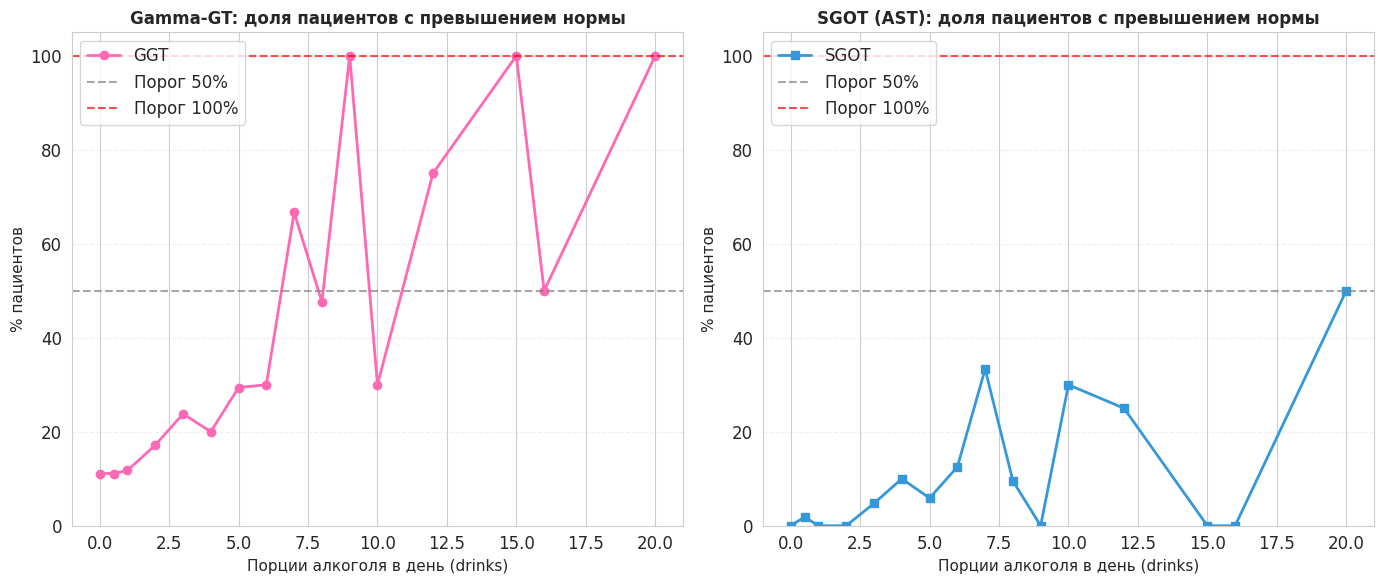

In [ ]:
# @title
results = []
for level in sorted(df['drinks'].unique()):
    subset = df[df['drinks'] == level]
    n = len(subset)
    ggt_pct = (subset['gammagt'] > ggt_norm).mean() * 100
    sgot_pct = (subset['sgot'] > sgot_norm).mean() * 100
    results.append({'Drinks': level, 'GGT_%': ggt_pct, 'SGOT_%': sgot_pct})

res_df = pd.DataFrame(results)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# График для GGT
axes[0].plot(res_df['Drinks'], res_df['GGT_%'], marker='o', color='hotpink', linewidth=2, markersize=6, label='GGT')
axes[0].axhline(50, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, label='Порог 50%')
axes[0].axhline(100, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Порог 100%')
axes[0].set_title('Gamma-GT: доля пациентов с превышением нормы', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Порции алкоголя в день (drinks)', fontsize=11)
axes[0].set_ylabel('% пациентов', fontsize=11)
axes[0].set_ylim(0, 105)
axes[0].grid(axis='y', alpha=0.3, linestyle='--')
axes[0].legend(loc='upper left')

# График для SGOT
axes[1].plot(res_df['Drinks'], res_df['SGOT_%'], marker='s', color='#3498db', linewidth=2, markersize=6, label='SGOT')
axes[1].axhline(50, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, label='Порог 50%')
axes[1].axhline(100, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Порог 100%')
axes[1].set_title('SGOT (AST): доля пациентов с превышением нормы', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Порции алкоголя в день (drinks)', fontsize=11)
axes[1].set_ylabel('% пациентов', fontsize=11)
axes[1].set_ylim(0, 105)
axes[1].grid(axis='y', alpha=0.3, linestyle='--')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

— Вот оно как оказывается выглядит — восхищённо произнесла исследовательница, любящая графики.

— Да, но, как можно было предположить, у нас нет значения, с которого все поголовно имеют превышения уровней ферментов — заметил Старец.

— Тогда предлагаю записать всё в наш блокнотик — сказала вторая исследовательница.

In [ ]:
# @title
from IPython.display import HTML

HTML("""
<div style="background-color: #fff9e6; border-left: 5px solid hotpink; padding: 22px; border-radius: 8px; margin: 15px 0; box-shadow: 0 2px 5px rgba(0,0,0,0.05); font-family: sans-serif;">

    <h3 style="color: #d81b60; margin-top: 0; margin-bottom: 20px; font-size: 19px;">Пороговые значения потребления алкоголя</h3>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">1. Минимальное употребление (0.5 пинты/день)</h4>
        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
            <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
                При потреблении 0.5 пинты алкоголя в день ферменты печени не выходят за пределы нормальных значений у подавляющего большинства пациентов. Это подтверждает, что минимальные дозы не вызывают статистически значимого токсического эффекта.
            </p>
        </div>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6; margin-bottom: 20px;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">2. Порог 50% превышений (каждый второй)</h4>
        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
        <p style="font-size: 15px; color: #333; line-height: 1.8; margin: 0;">
            Анализ показывает, что для GGT порог в 50% превышений стабильно удерживается начиная с 12 порций в день. Для SGOT этот же порог достигается только на отметке 20 порций в день. Разница наглядно доказывает, что GGT является более чувствительным и ранним маркером алкогольной нагрузки на печень.
        </p>
        </div>
    </div>

    <div style="background-color: white; padding: 18px; border-radius: 6px; border: 1px dashed #ffb3c6;">
        <h4 style="color: #d81b60; margin-top: 0; margin-bottom: 15px; font-size: 16px;">3. Порог 100% превышений (гарантированная патология)</h4>
        <div style="background-color: #fff0f5; padding: 15px; border-radius: 6px; border-left: 4px solid hotpink;">
            <p style="font-size: 15px; color: #333; line-height: 1.6; margin: 0;">
                Для GGT отметка в 100% достигается при конкретных значениях: 9, 15 и 20 порций в день. Для SGOT порог в 100% не достигается даже при максимальных дозах в выборке. Это объясняется высоким влиянием индивидуальных особенностей организма и тем, что это также фермент миокарда.
            </p>
        </div>
    </div>

</div>
""")

<a id="lab-resume-1"></a>

## Резюме лабораторной работы

> — Ну что ж, — сказал Старец, — наши заклинания отработали. Мы доказали стохастическую природу данных, проверили состоятельность оценок, отвергли нормальность и нашли истинные распределения.
>
> Юноша устало, но с улыбкой потёр виски:
>
> — И даже сравнили две выборки критерием Манна–Уитни.
>
> — Пришло время собрать всё воедино и посмотреть на картину целиком, —  сказала первая девушка.

In [ ]:
# @title Итоговые метрики исследования
import pandas as pd

summary_metrics = pd.DataFrame({
    "Величина": ["drinks (алкоголь)", "gammagt (фермент)", "sgot (фермент)"],
    "Тип": ["Дискретная", "Непрерывная", "Непрерывная"],
    "Лучшая модель (по AIC)": ["Poisson / Отриц. биномиальное", "Lognormal", "Lognormal"],
    "Нормальность (Шапиро-Уилк)": ["Отвергнута (p < 0.001)", "Отвергнута (p < 0.001)", "Отвергнута (p < 0.001)"],
    "Ключевой вывод": ["Сверхдисперсия", "Тяжёлый правый хвост", "Умеренная асимметрия"]
})

display(summary_metrics)

print("\nГипотеза о различии групп (Манна-Уитни):")
print("   Группы: drinks ≤ 5 (n=257) vs drinks > 5 (n=88)")
print("   Результат: p-value < 0.001, H₀ отвергнута. Распределения статистически значимо различаются.")

,Величина,Тип,Лучшая модель (по AIC),Нормальность (Шапиро-Уилк),Ключевой вывод
0,drinks (алкоголь),Дискретная,Poisson / Отриц. биномиальное,Отвергнута (p < 0.001),Сверхдисперсия
1,gammagt (фермент),Непрерывная,Lognormal,Отвергнута (p < 0.001),Тяжёлый правый хвост
2,sgot (фермент),Непрерывная,Lognormal,Отвергнута (p < 0.001),Умеренная асимметрия



Гипотеза о различии групп (Манна-Уитни):
   Группы: drinks ≤ 5 (n=257) vs drinks > 5 (n=88)
   Результат: p-value < 0.001, H₀ отвергнута. Распределения статистически значимо различаются.


> — Стоп, — вдруг сказал юноша. — Мы сделали столько всего: считали, строили графики, отвергали гипотезы. Но если меня спросят на совете старейшин, зачем мы делали каждый шаг — что я отвечу?
>
> Первая девушка улыбнулась:
> — Отличный вопрос. Давай откроем последнюю страницу блокнота и запишем нашу дорожную карту. Чтобы каждый шаг вёл к следующему, как ступени лестницы.

## Дорожная карта исследования

> — Цифры собраны, — сказала вторая девушка. — Но мы так и не ответили на главный вопрос, с которого началось наше путешествие.
>
> Юноша нахмурился:
> — Виновата ли лавка в том, что люди болеют? Или это просто совпадение?

In [ ]:
# @title Нарушение медицинских норм
GGT_NORM = 48
SGOT_NORM = 40

low_viol_ggt = (low_drinks['gammagt'] > GGT_NORM).mean() * 100
low_viol_sgot = (low_drinks['sgot'] > SGOT_NORM).mean() * 100

high_viol_ggt = (high_drinks['gammagt'] > GGT_NORM).mean() * 100
high_viol_sgot = (high_drinks['sgot'] > SGOT_NORM).mean() * 100

final_verdict = pd.DataFrame({
    "Группа населения": [
        "Умеренно пьющие (≤ 5 порций)",
        "Много пьющие (> 5 порций)"
    ],
    "Размер группы": [len(low_drinks), len(high_drinks)],
    "Нарушение нормы GGT (>48 Ед/л)": [f"{low_viol_ggt:.1f}%", f"{high_viol_ggt:.1f}%"],
    "Нарушение нормы SGOT (>40 Ед/л)": [f"{low_viol_sgot:.1f}%", f"{high_viol_sgot:.1f}%"],
    "Статус печени": [
        "Преимущественно в норме",
        "Высокий риск поражения"
    ]
})

display(final_verdict)

,Группа населения,Размер группы,Нарушение нормы GGT (>48 Ед/л),Нарушение нормы SGOT (>40 Ед/л),Статус печени
0,Умеренно пьющие (≤ 5 порций),257,16.0%,3.5%,Преимущественно в норме
1,Много пьющие (> 5 порций),88,43.2%,15.9%,Высокий риск поражения


> — Смотрите! — воскликнула первая девушка. — У тех, кто пьёт умеренно, нарушение GGT всего в ~11% случаев, а SGOT — менее чем в 2%.
>
> Юноша проследил взглядом на второй столбец:
> — А вот у много пьющих картина мрачнее. Почти половина имеет повышенный GGT, а средний уровень фермента уже пересекает красную черту нормы в 48 Ед/л.
>
> — Значит, лавка не виновата сама по себе, — сделала вывод вторая девушка. — Алкоголь в малых дозах не разрушает печень большинству людей. Проблема начинается там, где заканчивается мера.

## Концовка

> Через неделю после возвращения в академию исследователи представили свой отчёт Совету Старейшин.
>
> Лавку не закрыли. Вместо этого на её двери появилась новая медная табличка, выгравированная самим юношей:
>
> **"Внимание! Чрезмерное употребление (>5 порций в день) статистически значимо повышает риск поражения печени. Пейте умеренно, алкоголь не вредит, алкоголизм — убивает. "**

In [ ]:
# @title cat_mark_table

from IPython.display import HTML, display

display(HTML("""
<div style="
    background-color: #fff9e6;
    border-left: 6px solid #ff69b4;
    padding: 26px 28px;
    border-radius: 8px;
    margin: 20px 0;
    box-shadow: 0 4px 10px rgba(0,0,0,0.08);
    font-family: 'Segoe UI', sans-serif;
">

    <h2 style="
        color: #ff69b4;
        margin-top: 0;
        margin-bottom: 22px;
        font-size: 24px;
        font-weight: 700;
    ">
        cat_mark_table
    </h2>

    <table style="
        width: 100%;
        border-collapse: separate;
        border-spacing: 0 10px;
        font-size: 15px;
        color: #333;
    ">

        <thead>
            <tr>
                <th style="
                    background-color: #ff69b4;
                    color: white;
                    padding: 13px 16px;
                    text-align: left;
                    border-radius: 8px 0 0 8px;
                    width: 140px;
                ">
                    cat_id
                </th>

                <th style="
                    background-color: #ff69b4;
                    color: white;
                    padding: 13px 16px;
                    text-align: left;
                    width: 210px;
                ">
                    notebook_link
                </th>

                <th style="
                    background-color: #ff69b4;
                    color: white;
                    padding: 13px 16px;
                    text-align: left;
                    border-radius: 0 8px 8px 0;
                ">
                    comment
                </th>
            </tr>
        </thead>

        <tbody>

            <tr style="background-color: white;">
                <td style="
                    padding: 14px 16px;
                    border-radius: 8px 0 0 8px;
                    font-weight: 700;
                    color: #ff69b4;
                ">
                    DATA
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #444;
                ">
                    current notebook
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #333;
                    border-radius: 0 8px 8px 0;
                ">
                    описание датасета и корректная интерпретация <code>selector</code>
                </td>
            </tr>

            <tr style="background-color: white;">
                <td style="
                    padding: 14px 16px;
                    border-radius: 8px 0 0 8px;
                    font-weight: 700;
                    color: #ff69b4;
                ">
                    RV
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #444;
                ">
                    current notebook
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #333;
                    border-radius: 0 8px 8px 0;
                ">
                    3 случайные величины и их стохастическая природа
                </td>
            </tr>

            <tr style="background-color: white;">
                <td style="
                    padding: 14px 16px;
                    border-radius: 8px 0 0 8px;
                    font-weight: 700;
                    color: #ff69b4;
                ">
                    EDA
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #444;
                ">
                    current notebook
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #333;
                    border-radius: 0 8px 8px 0;
                ">
                    описательные статистики, PMF, ECDF и гистограммы
                </td>
            </tr>

            <tr style="background-color: white;">
                <td style="
                    padding: 14px 16px;
                    border-radius: 8px 0 0 8px;
                    font-weight: 700;
                    color: #ff69b4;
                ">
                    NORM
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #444;
                ">
                    current notebook
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #333;
                    border-radius: 0 8px 8px 0;
                ">
                    Z-standardization и Min-Max normalization
                </td>
            </tr>

            <tr style="background-color: white;">
                <td style="
                    padding: 14px 16px;
                    border-radius: 8px 0 0 8px;
                    font-weight: 700;
                    color: #ff69b4;
                ">
                    DEP
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #444;
                ">
                    current notebook
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #333;
                    border-radius: 0 8px 8px 0;
                ">
                    Pearson и Spearman для трёх исследуемых пар
                </td>
            </tr>

            <tr style="background-color: white;">
                <td style="
                    padding: 14px 16px;
                    border-radius: 8px 0 0 8px;
                    font-weight: 700;
                    color: #ff69b4;
                ">
                    SAMPLE
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #444;
                ">
                    current notebook
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #333;
                    border-radius: 0 8px 8px 0;
                ">
                    выборка с возвращением и без возвращения
                </td>
            </tr>

            <tr style="background-color: white;">
                <td style="
                    padding: 14px 16px;
                    border-radius: 8px 0 0 8px;
                    font-weight: 700;
                    color: #ff69b4;
                ">
                    CONS
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #444;
                ">
                    current notebook
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #333;
                    border-radius: 0 8px 8px 0;
                ">
                    эмпирическая проверка состоятельности оценок
                </td>
            </tr>

            <tr style="background-color: white;">
                <td style="
                    padding: 14px 16px;
                    border-radius: 8px 0 0 8px;
                    font-weight: 700;
                    color: #ff69b4;
                ">
                    HYP
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #444;
                ">
                    current notebook
                </td>
                <td style="
                    padding: 14px 16px;
                    color: #333;
                    border-radius: 0 8px 8px 0;
                ">
                    Mann–Whitney для <code>drinks</code> и Gamma-GT
                </td>
            </tr>

        </tbody>

    </table>

</div>
"""))